In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv('/content/Ames Housing Dataset.csv')

In [3]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.shape

(1460, 81)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [7]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [9]:
df.isnull().sum().sum()

np.int64(7829)

In [10]:
df.duplicated().sum()

np.int64(0)

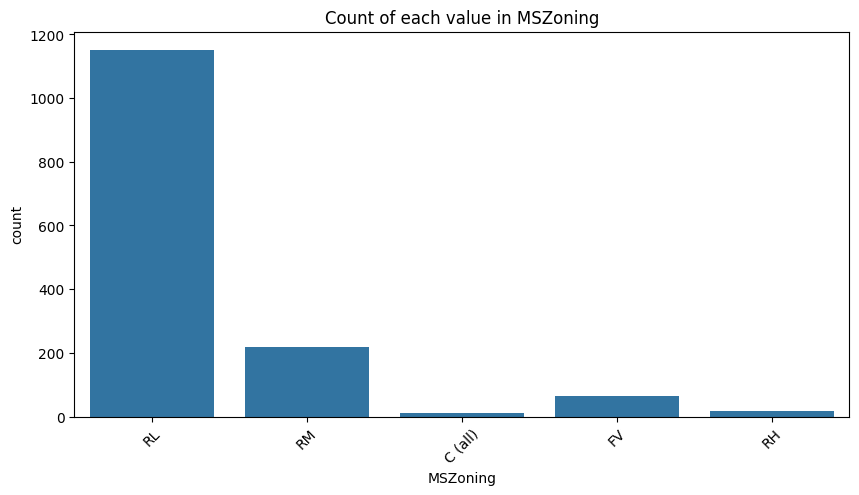

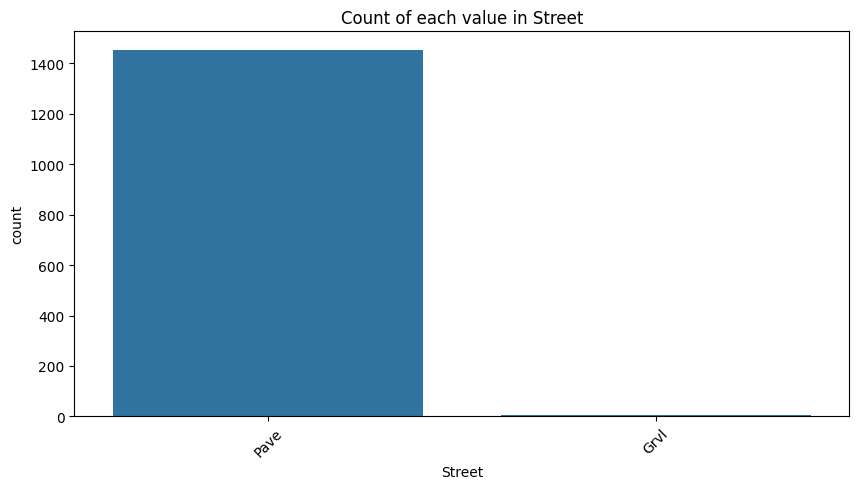

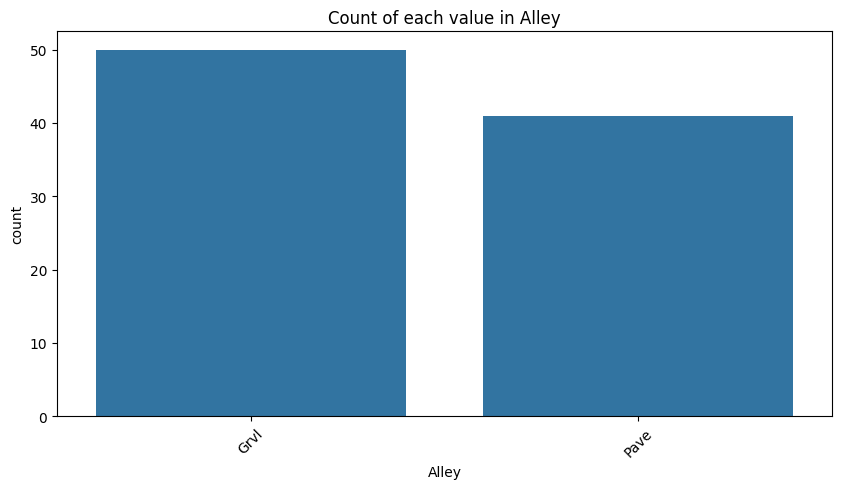

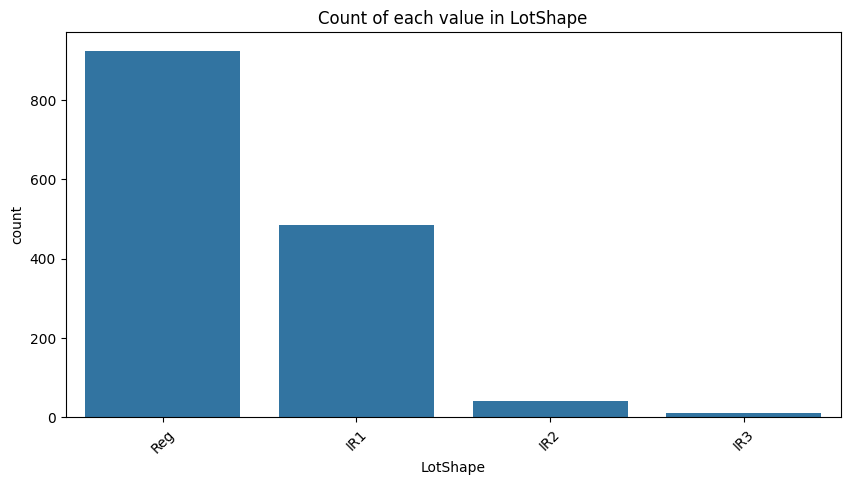

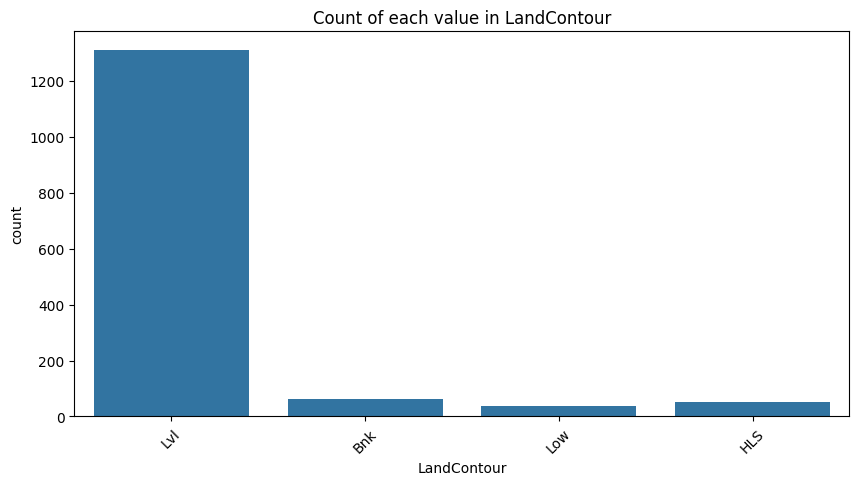

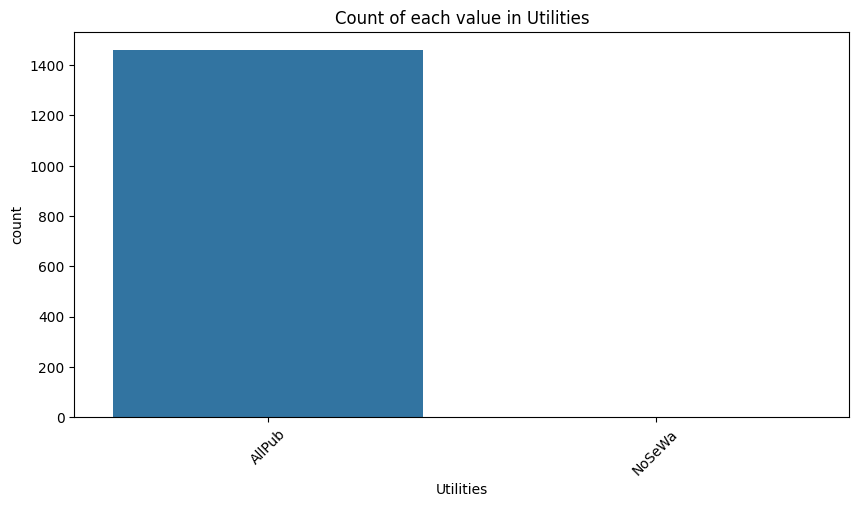

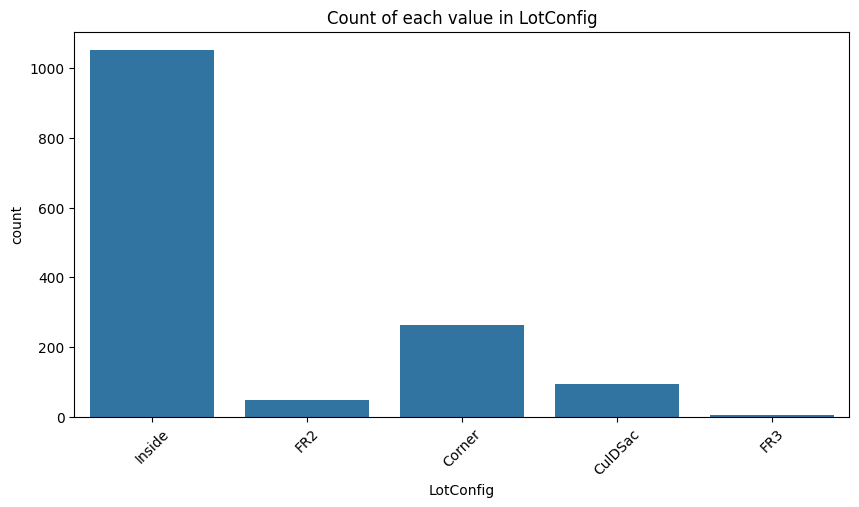

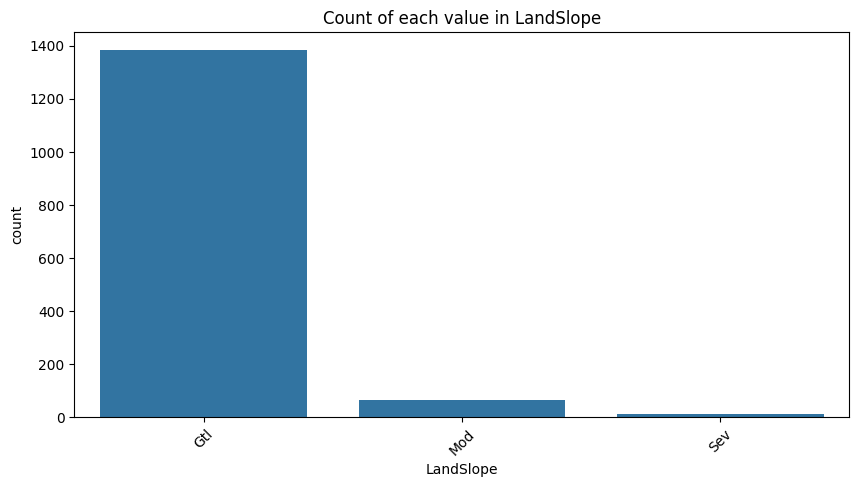

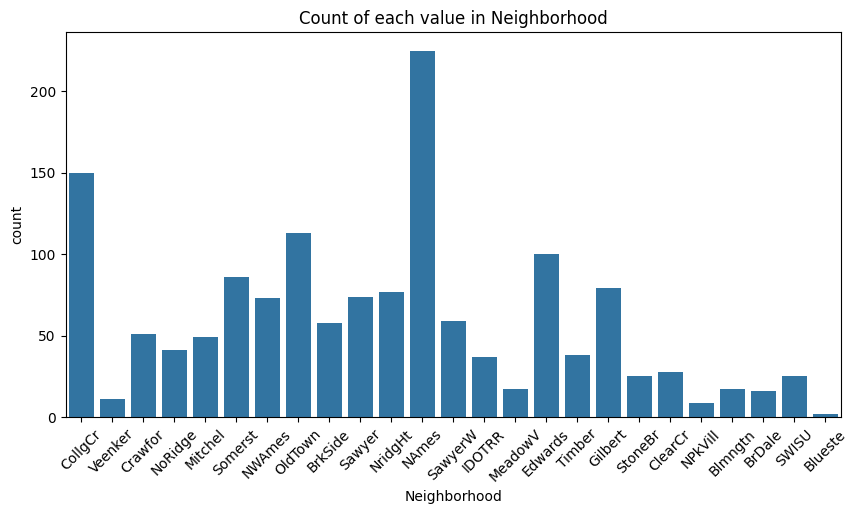

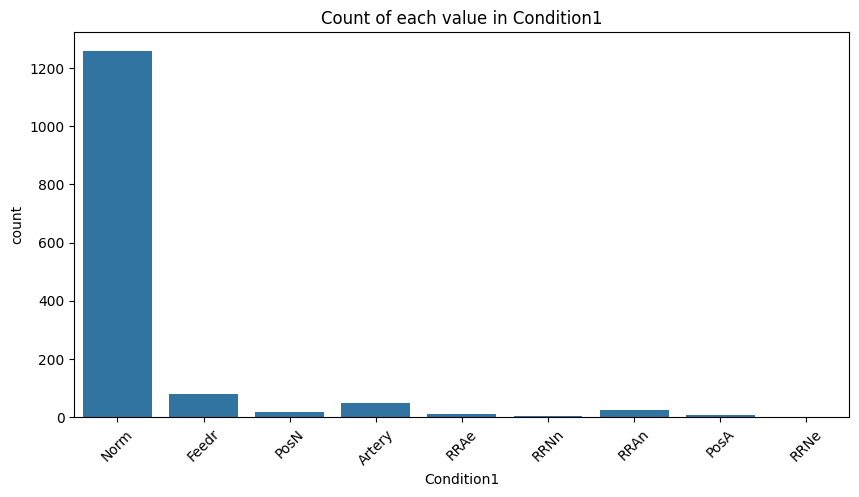

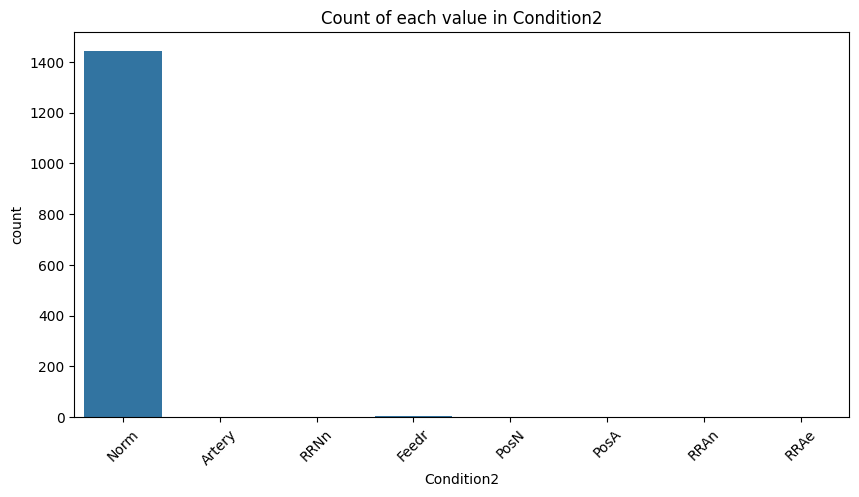

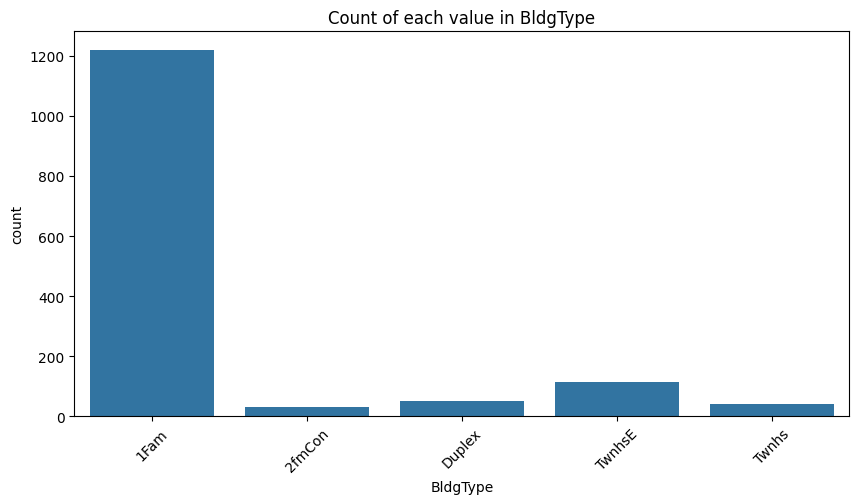

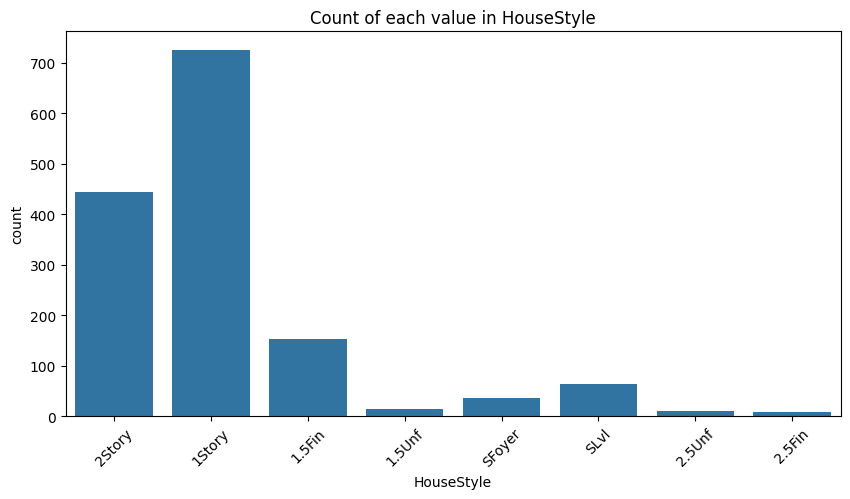

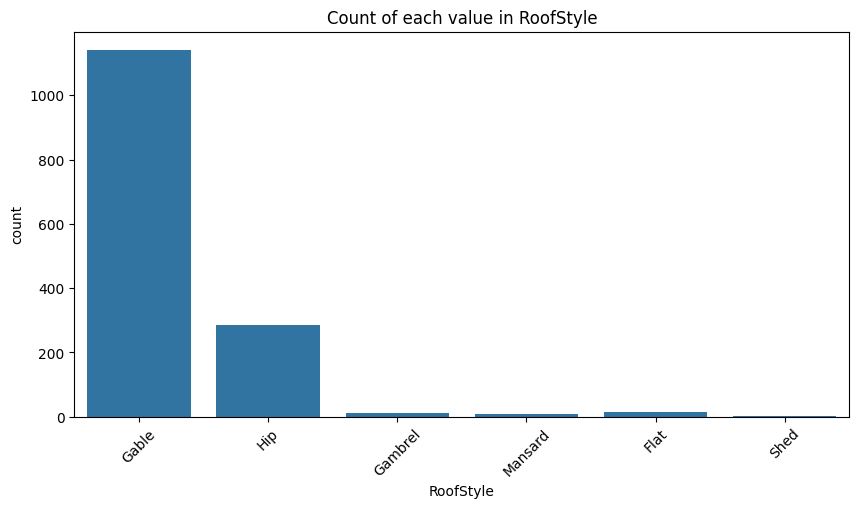

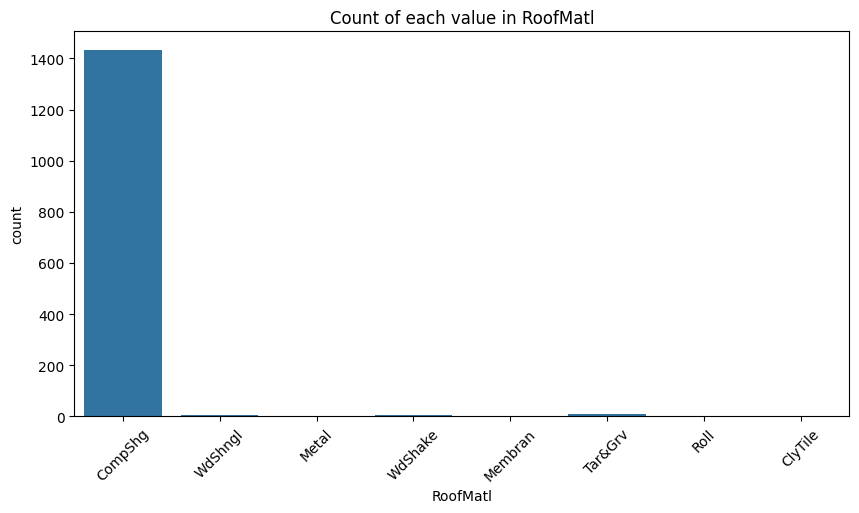

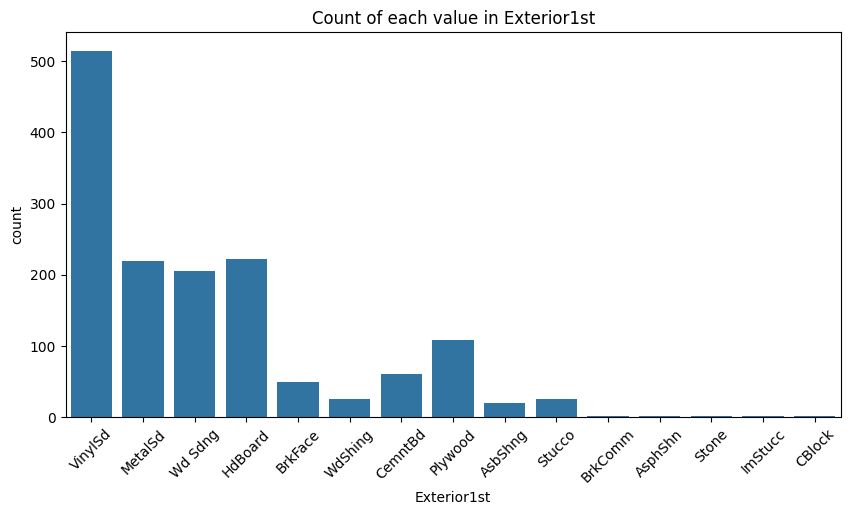

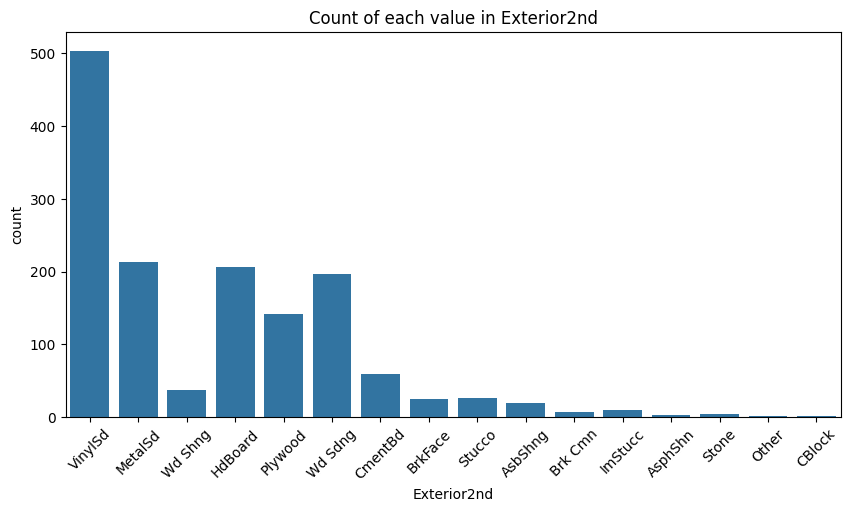

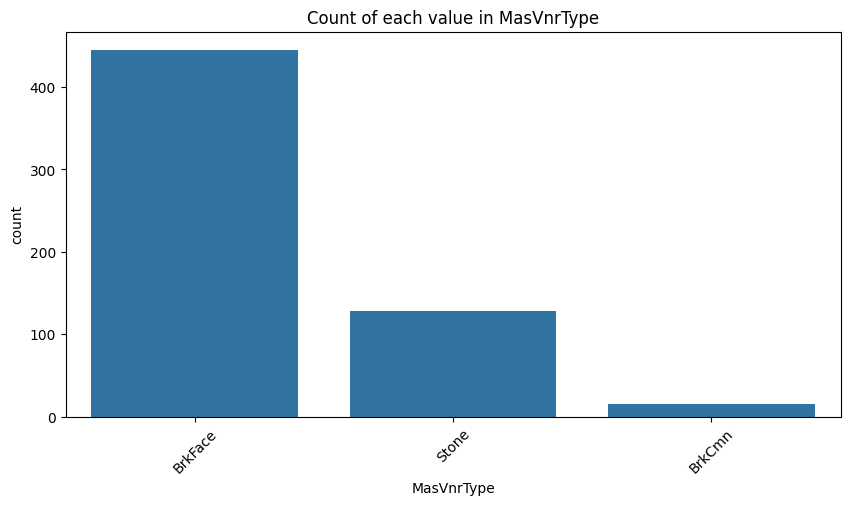

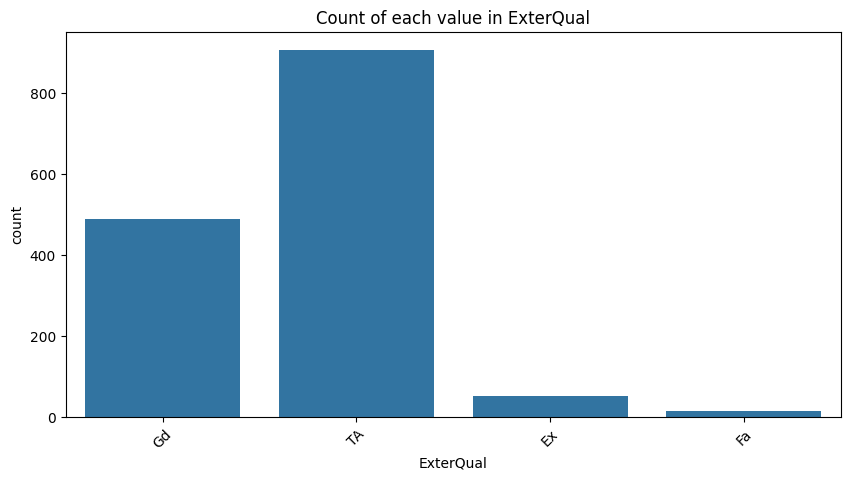

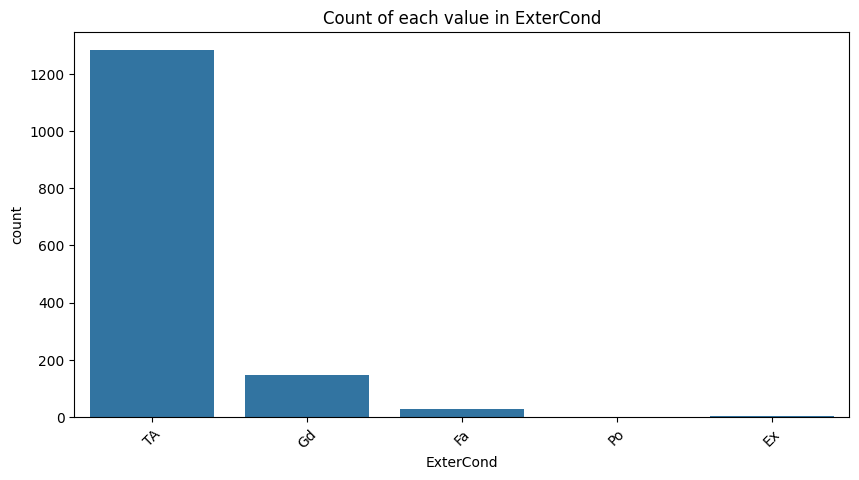

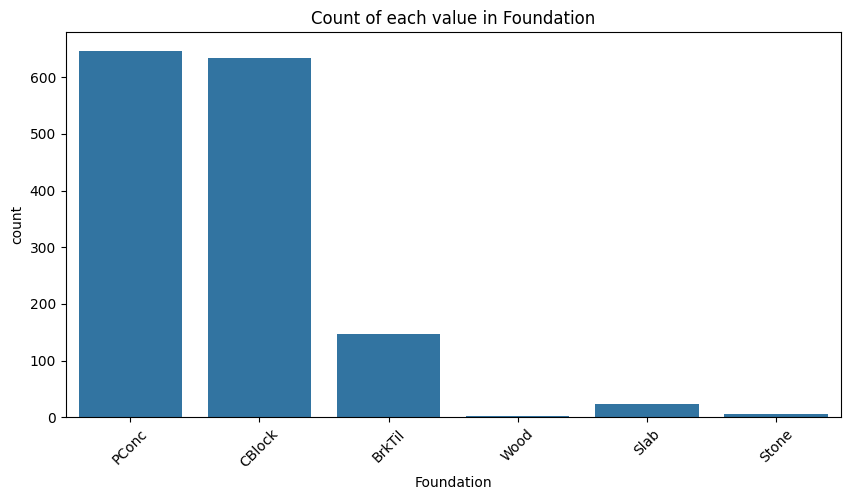

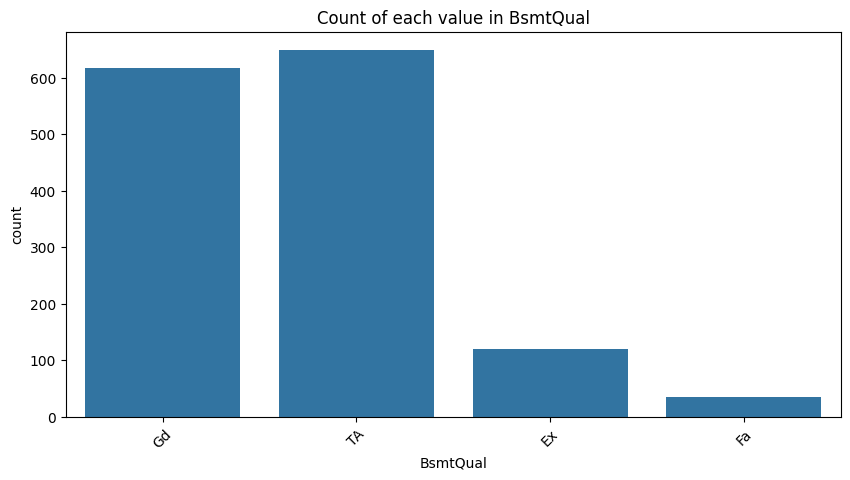

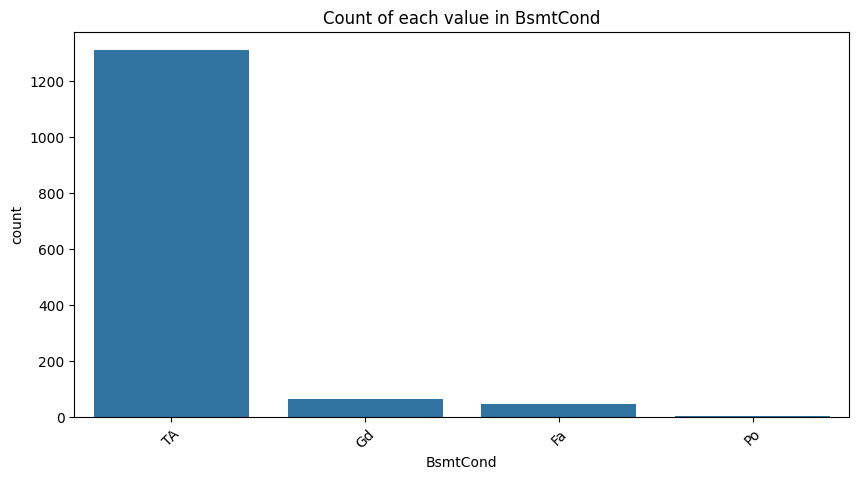

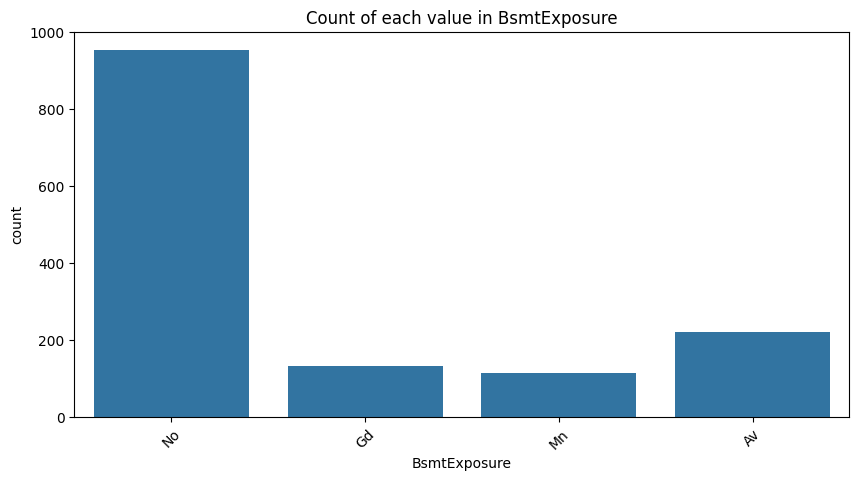

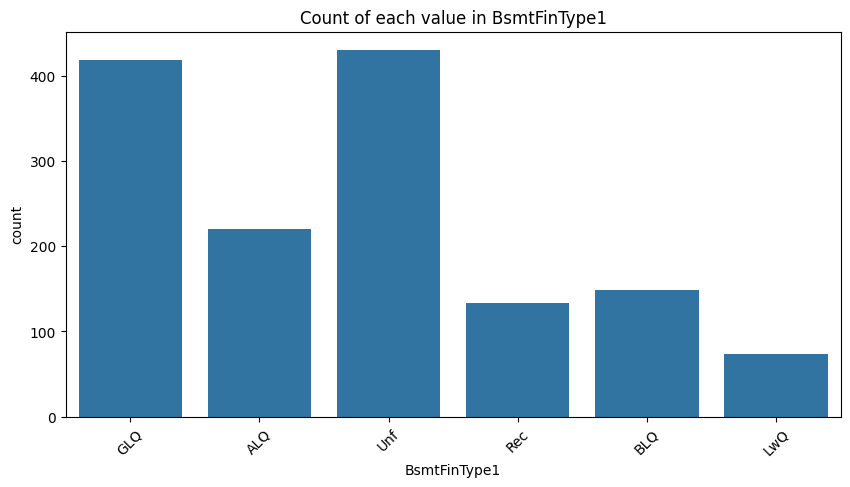

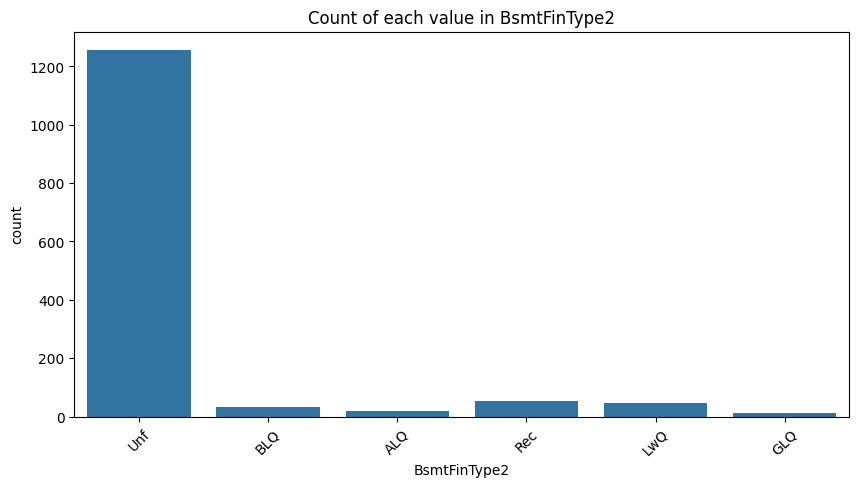

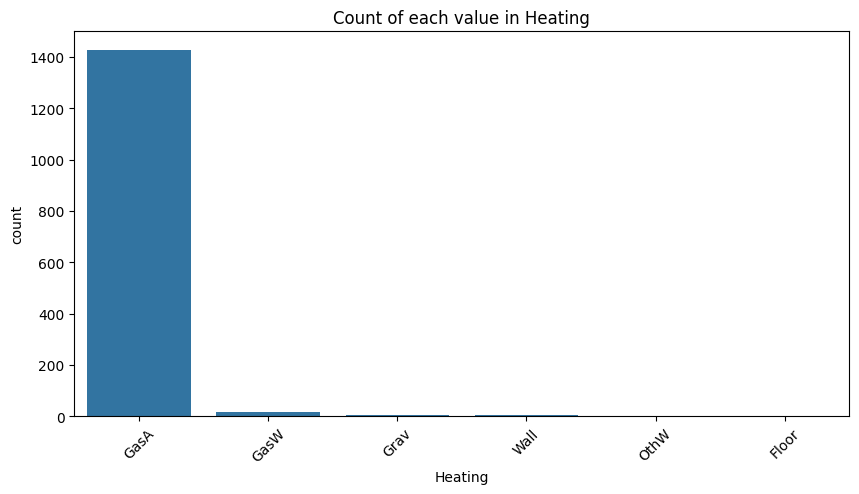

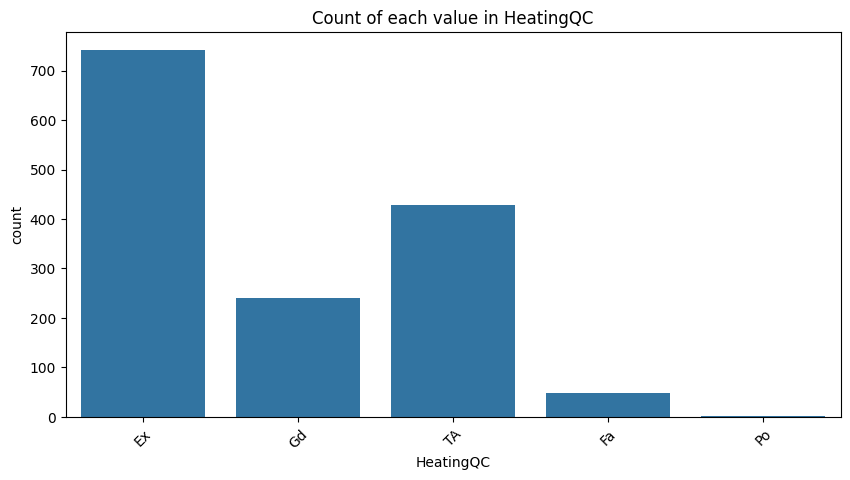

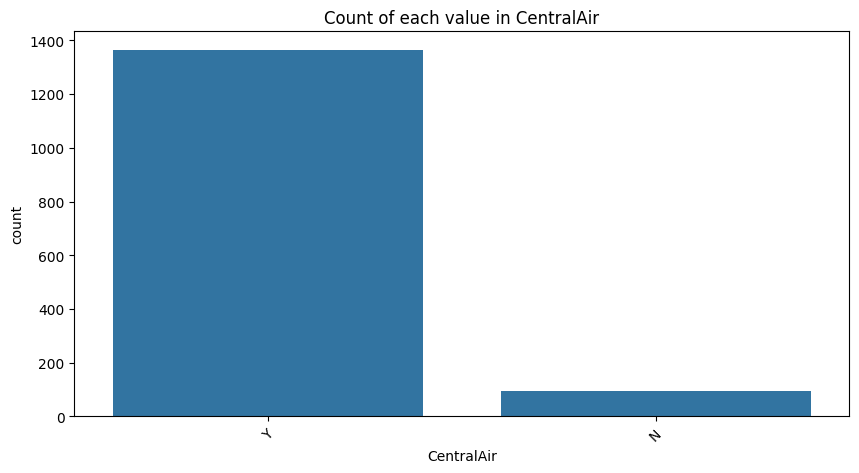

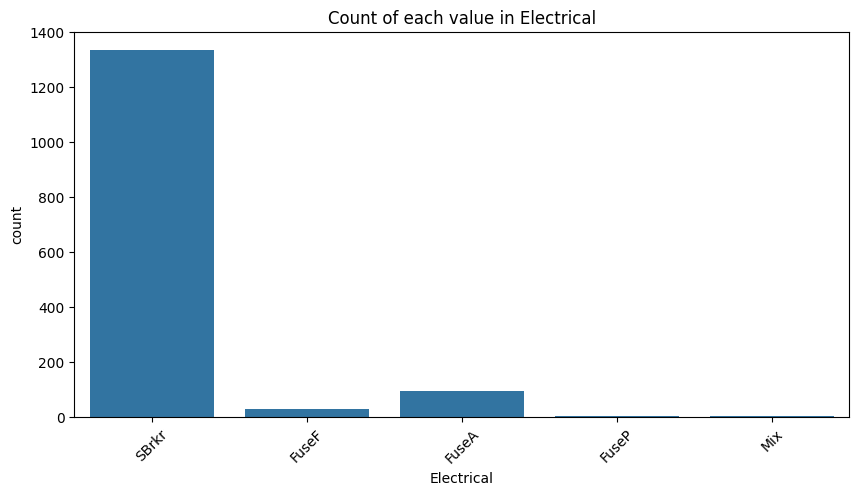

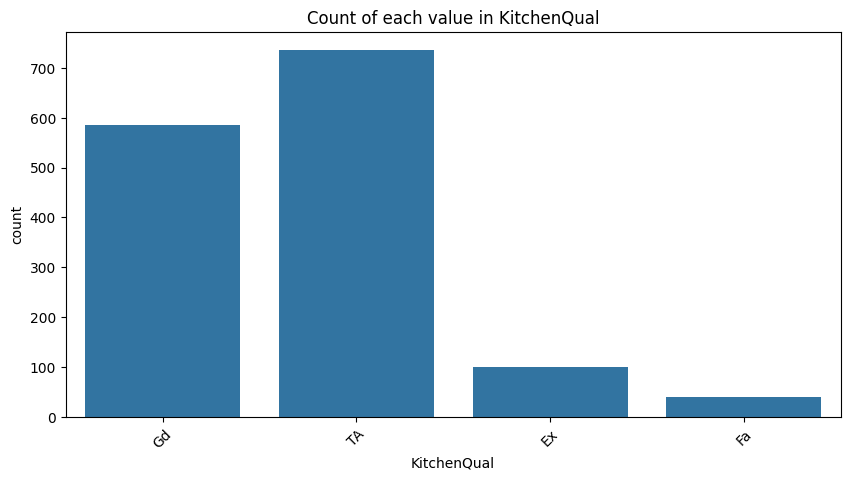

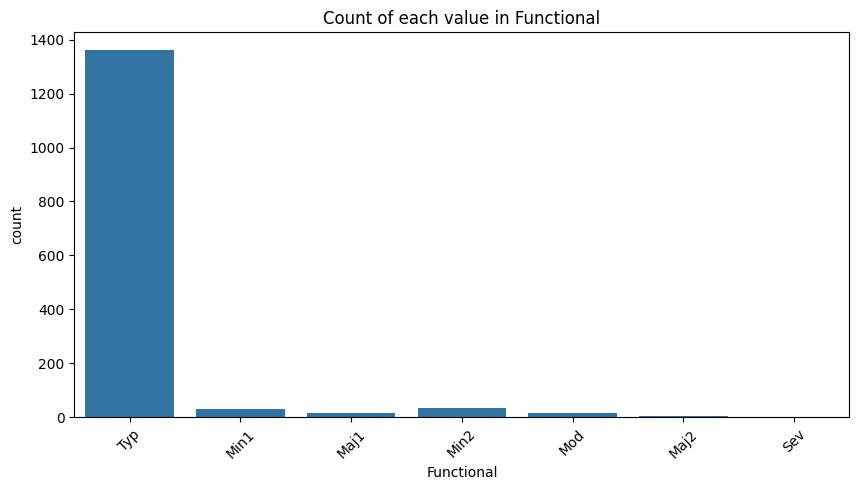

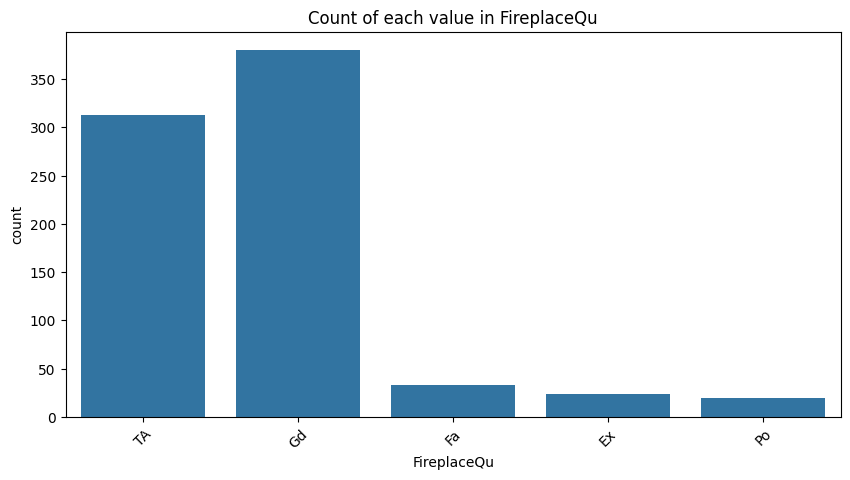

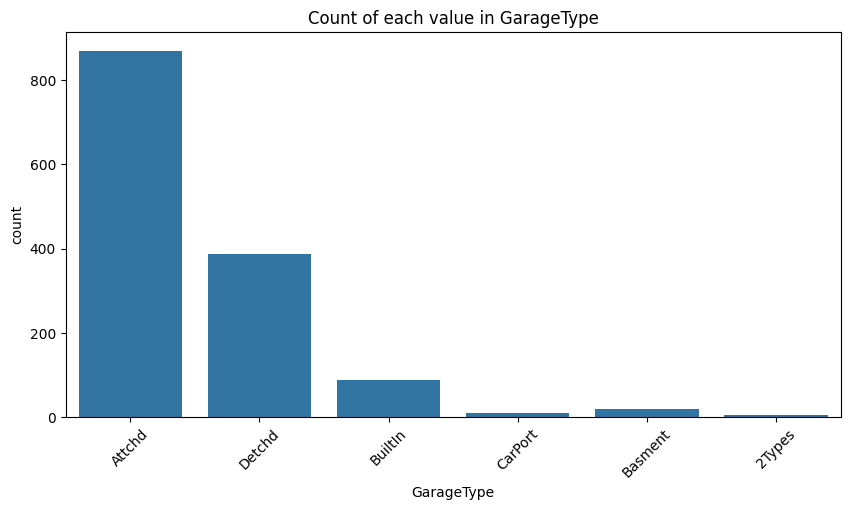

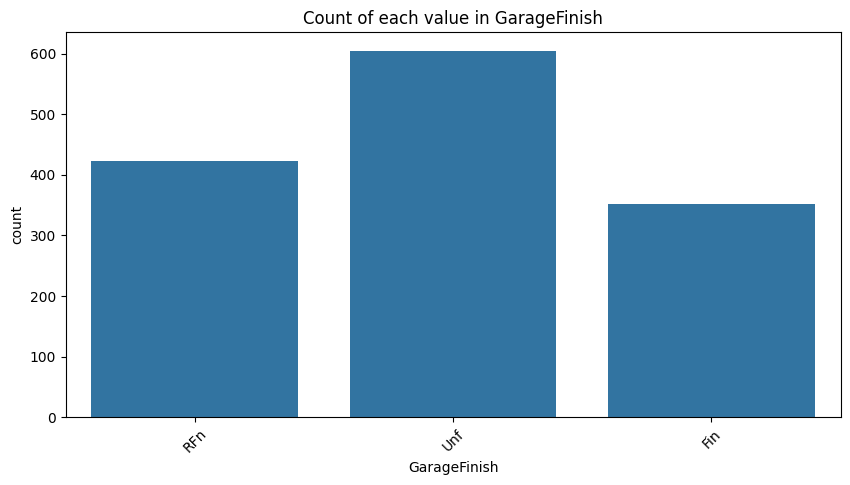

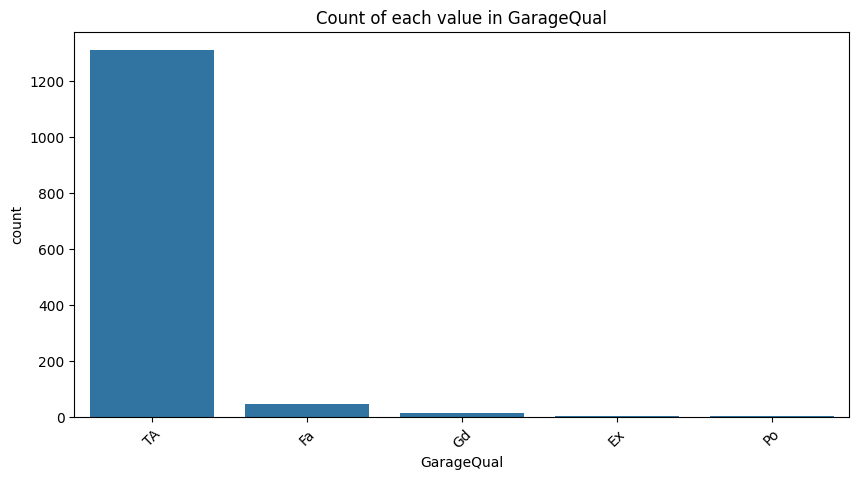

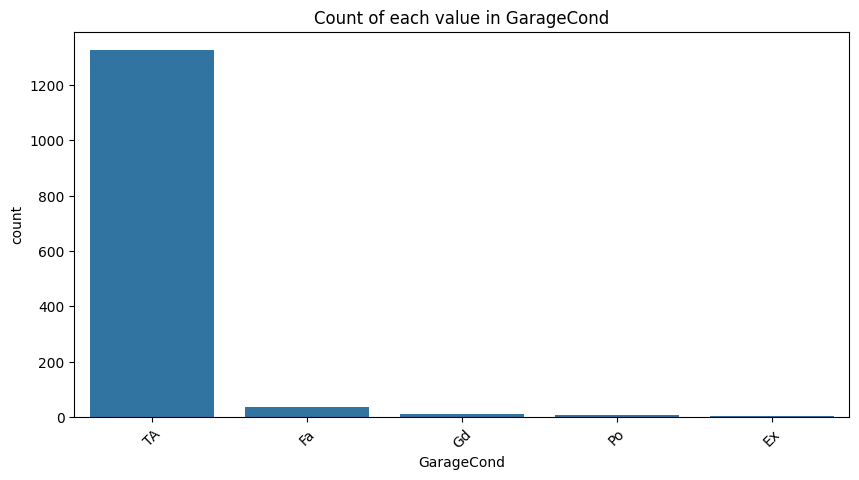

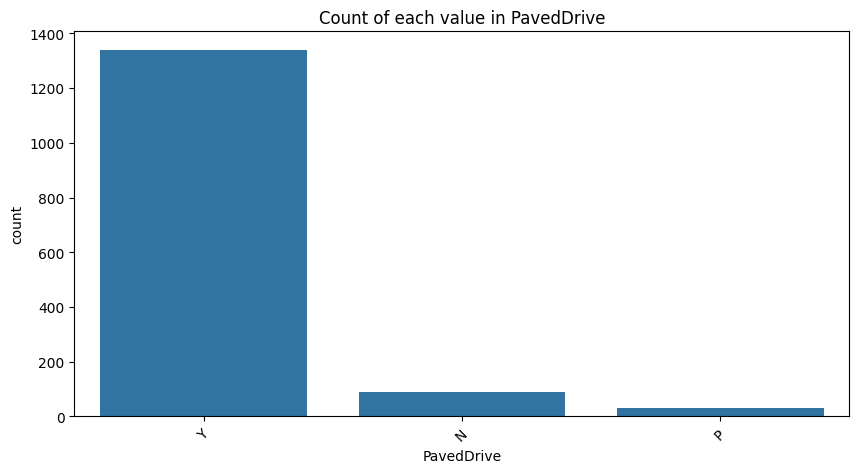

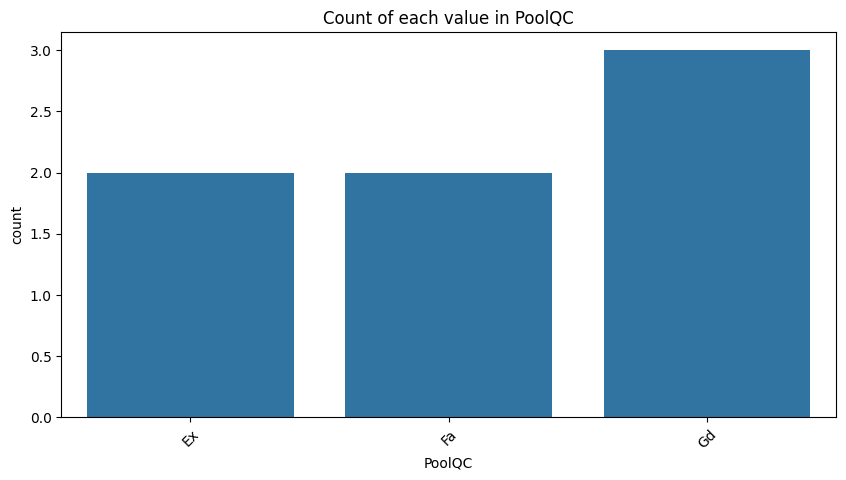

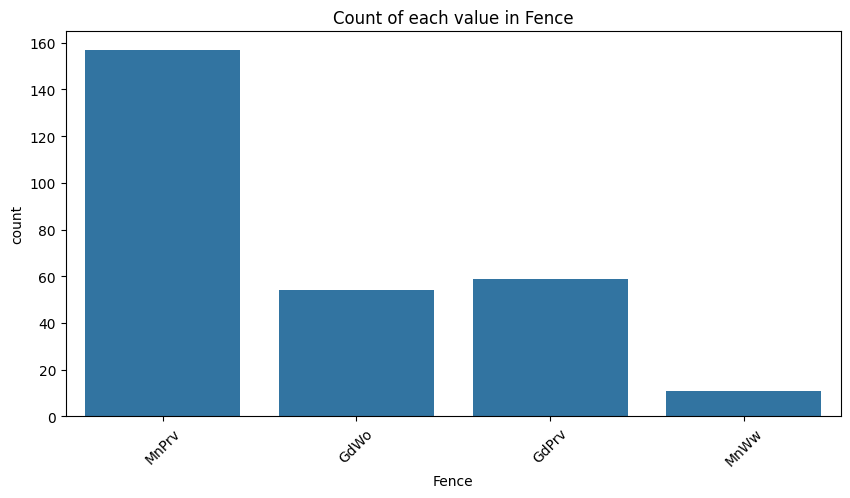

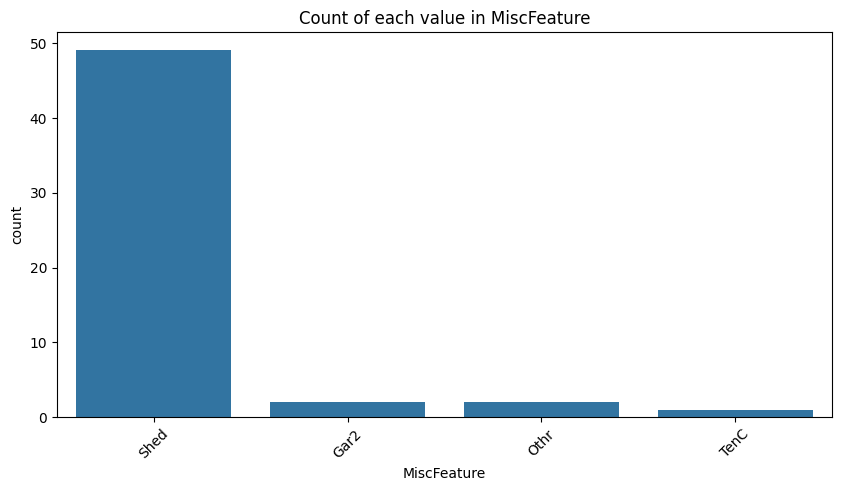

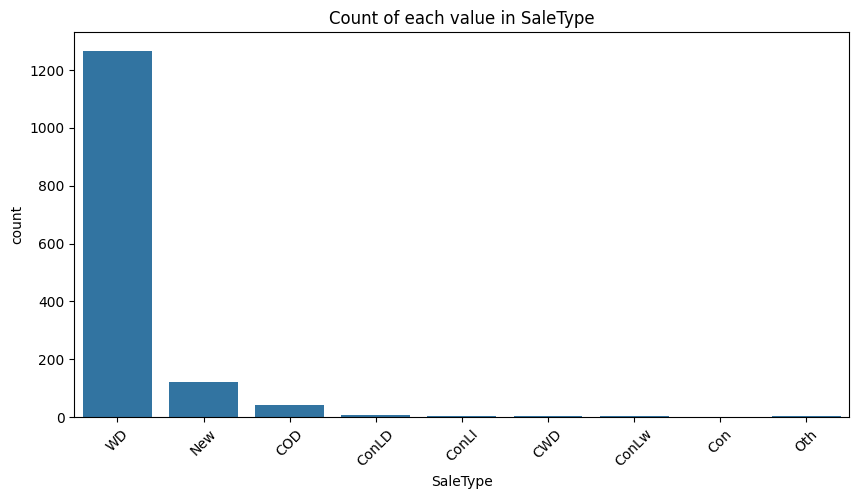

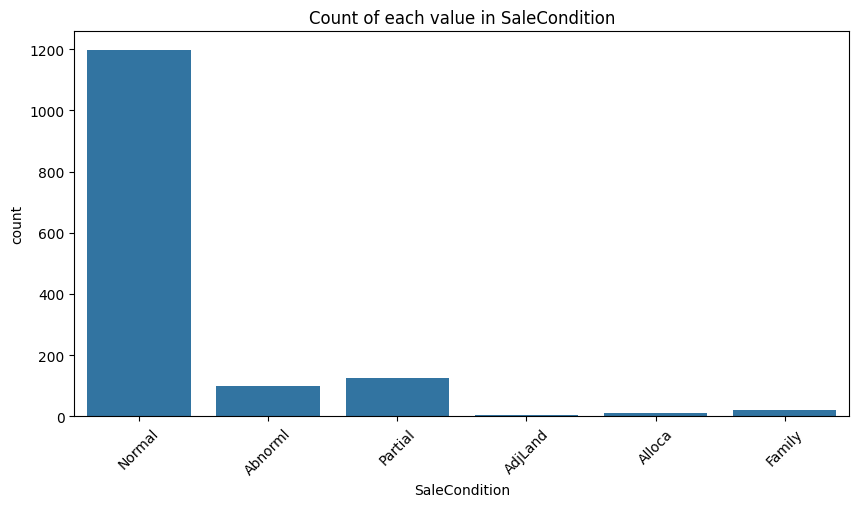

In [11]:
cat=df.select_dtypes(include='object')

for col in cat:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col)

    plt.title(f'Count of each value in {col}')
    plt.xticks(rotation=45)
    plt.show()

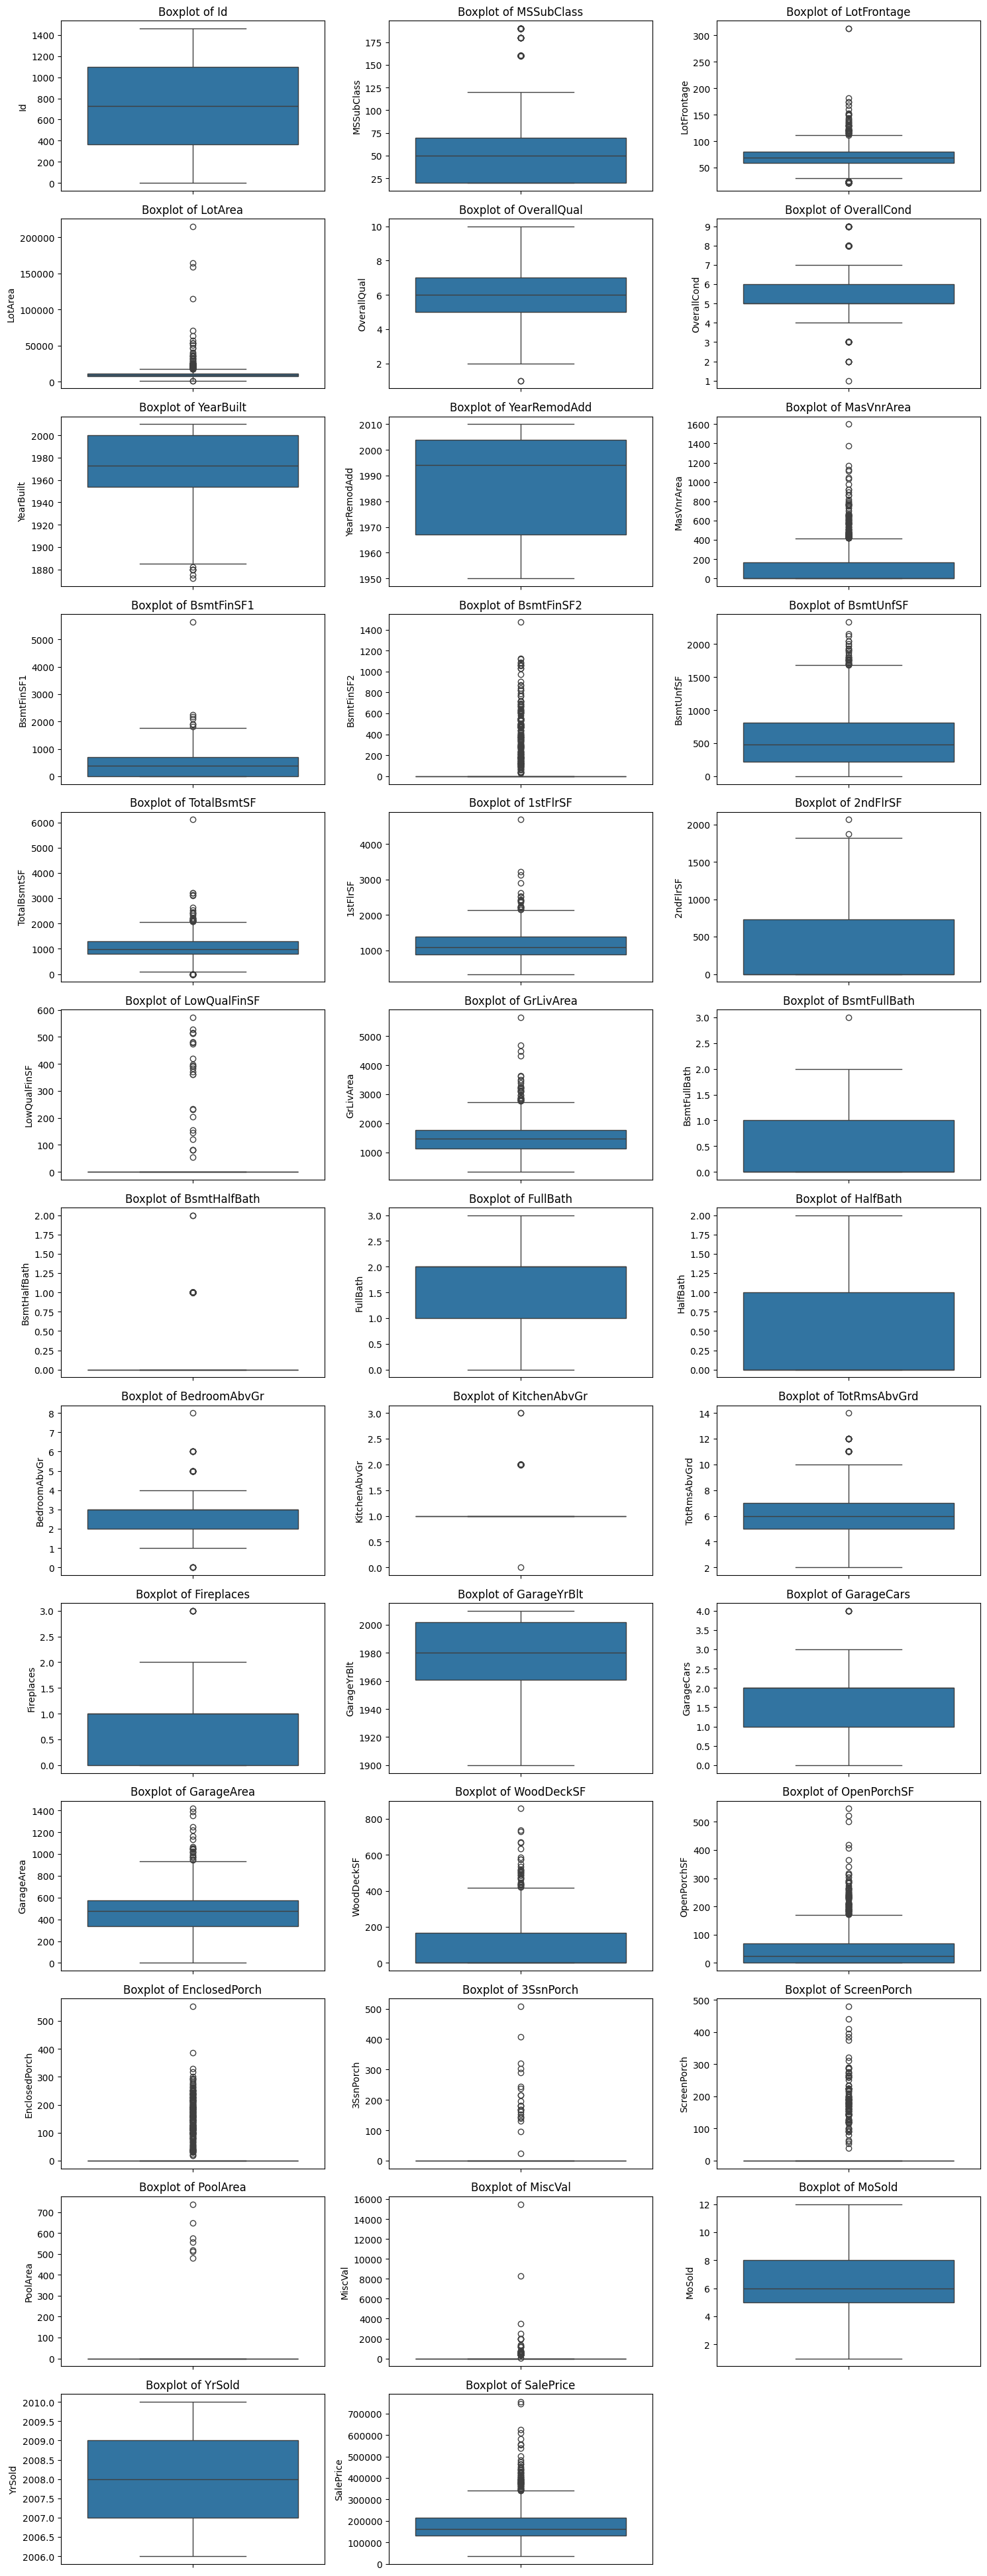

In [12]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
num_plots = len(numeric_cols)
cols_grid = 3
rows_grid = (num_plots + cols_grid - 1) // cols_grid

plt.figure(figsize=(15, 3 * rows_grid))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows_grid, cols_grid, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

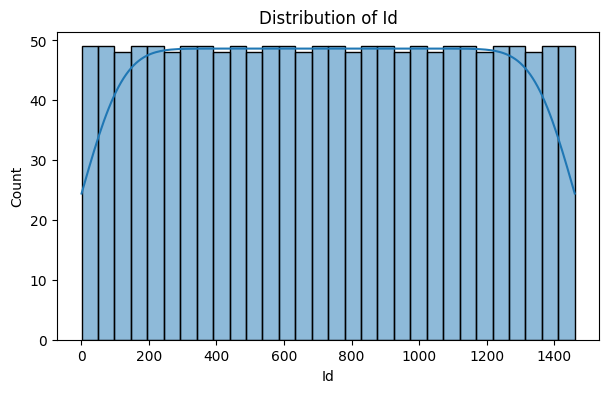

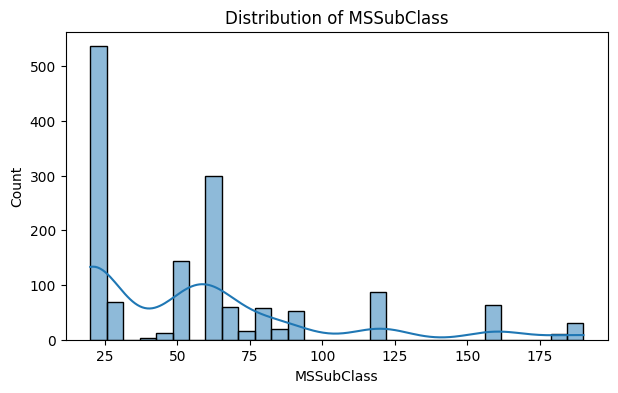

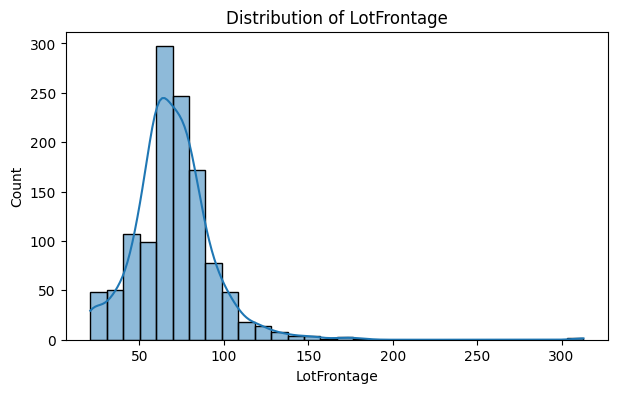

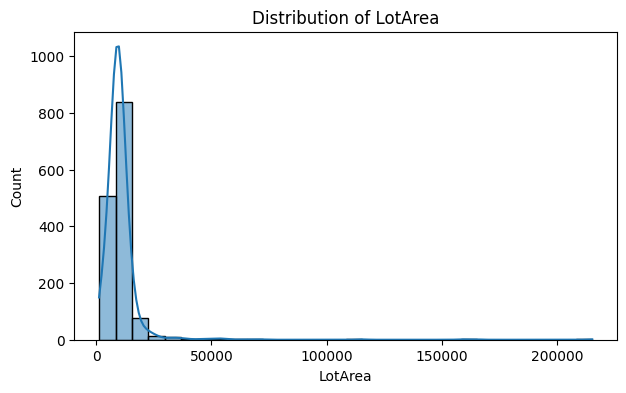

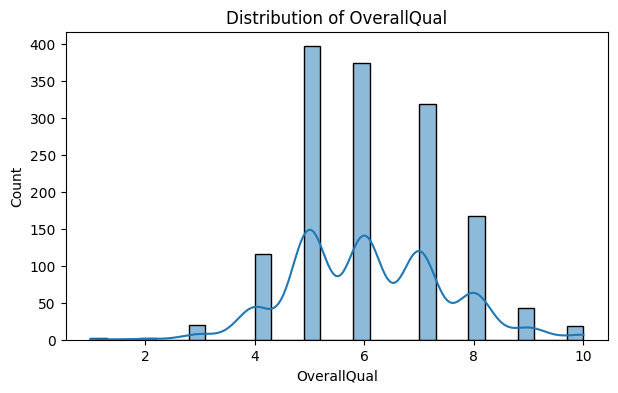

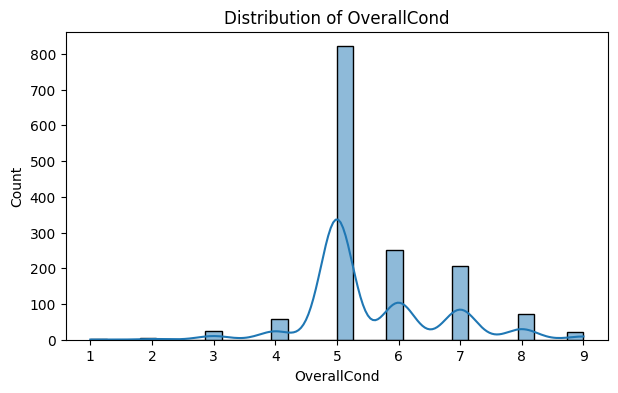

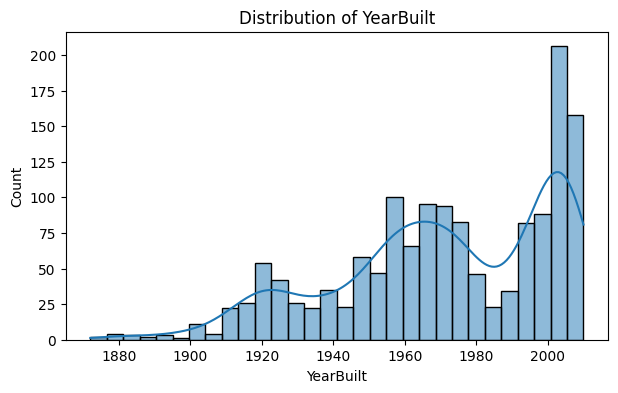

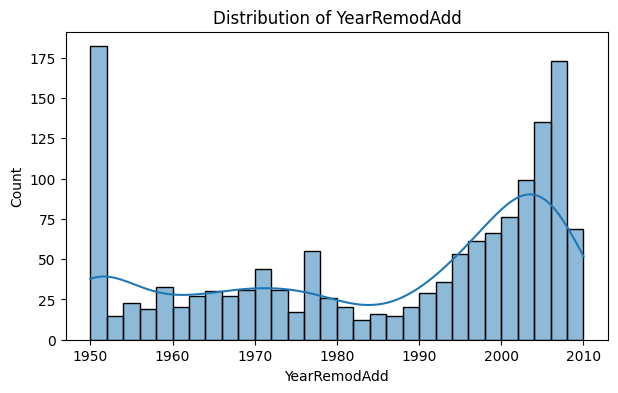

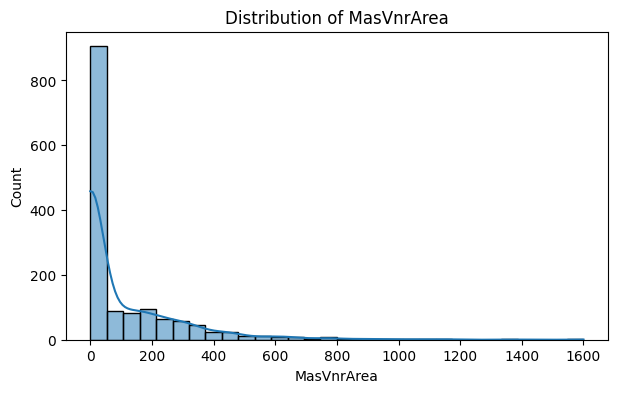

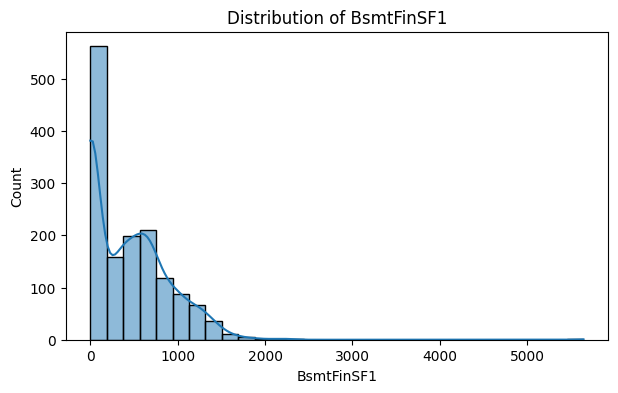

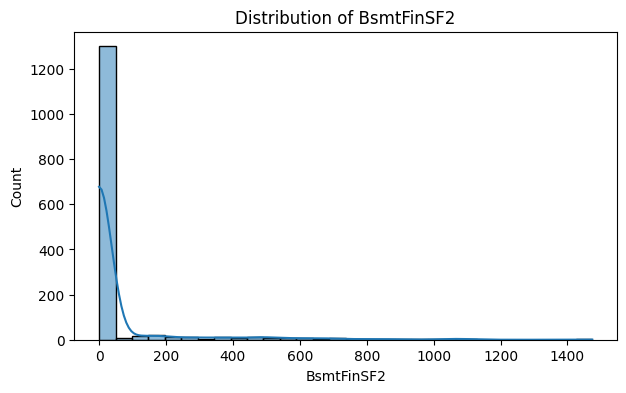

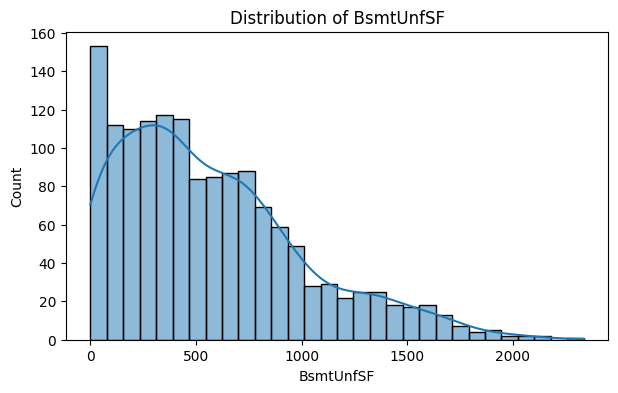

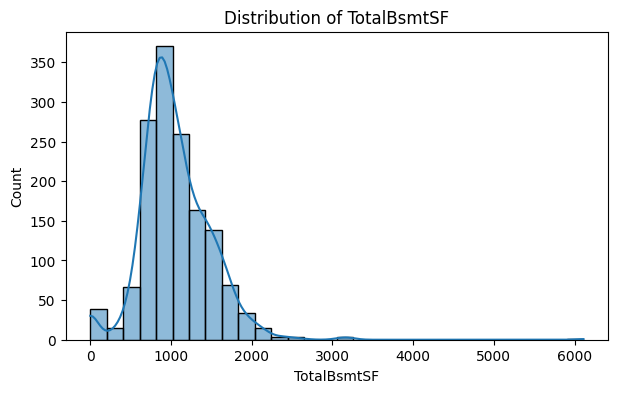

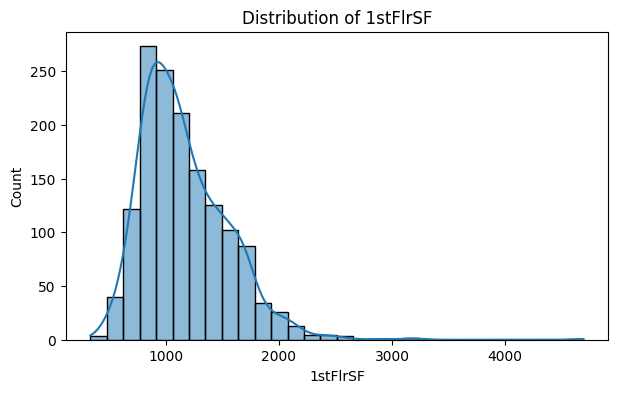

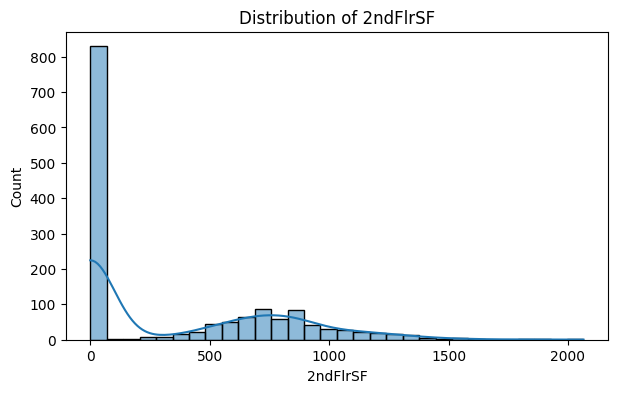

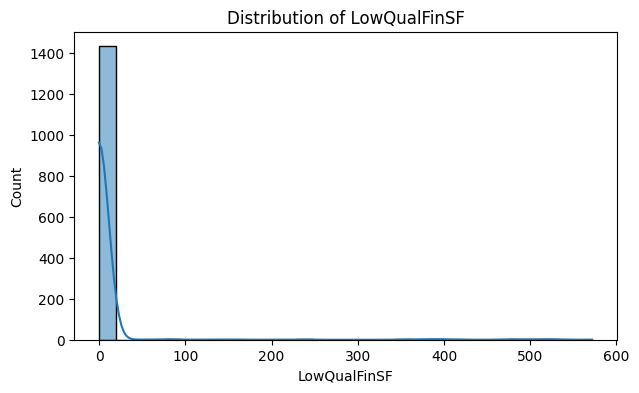

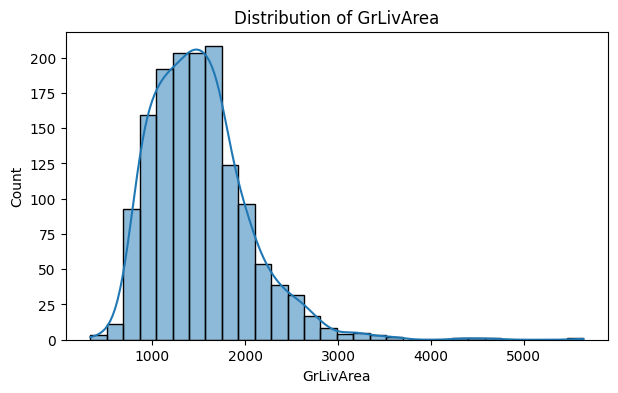

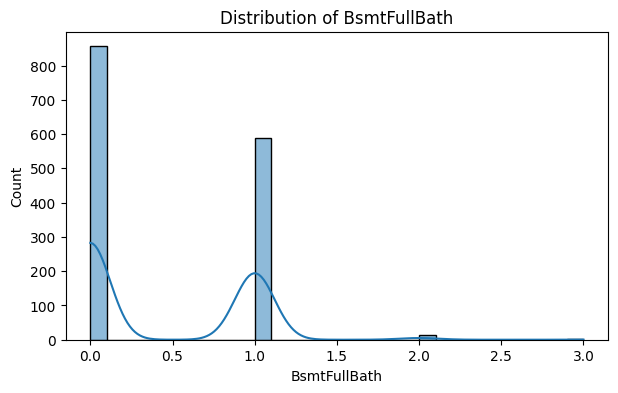

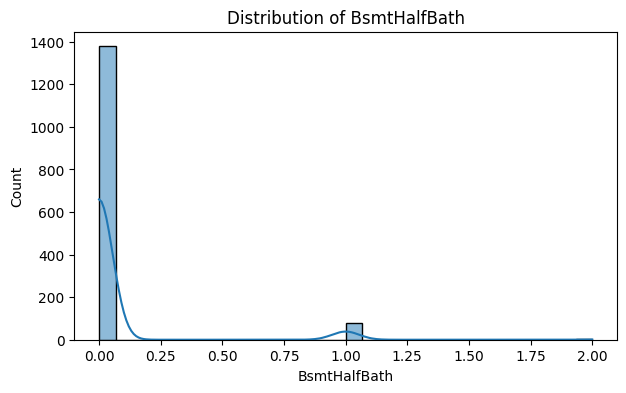

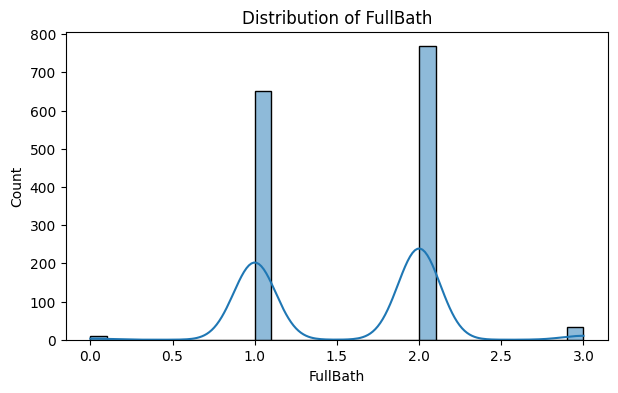

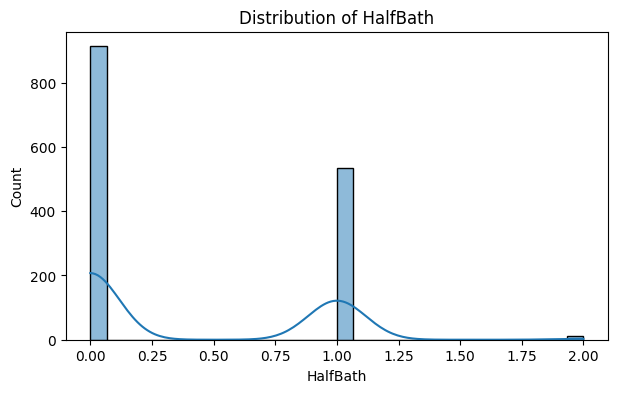

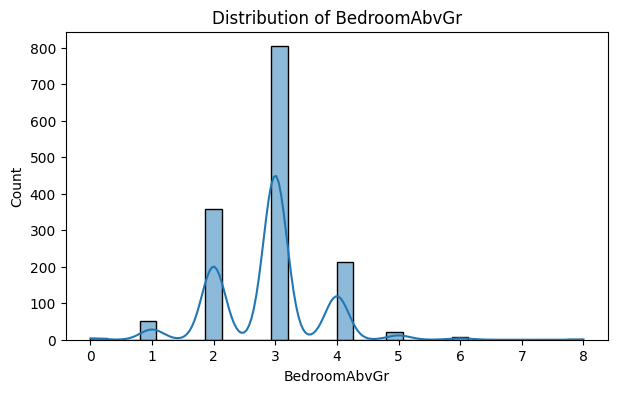

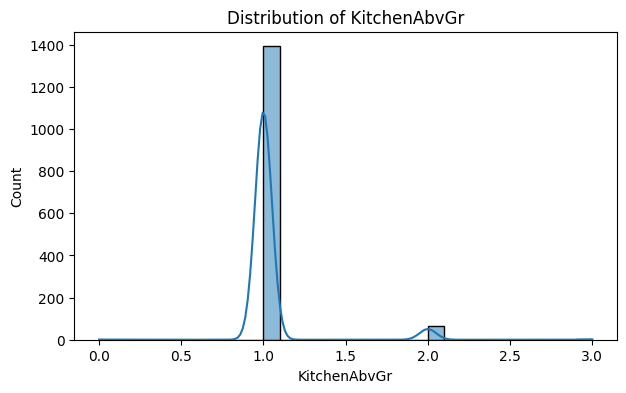

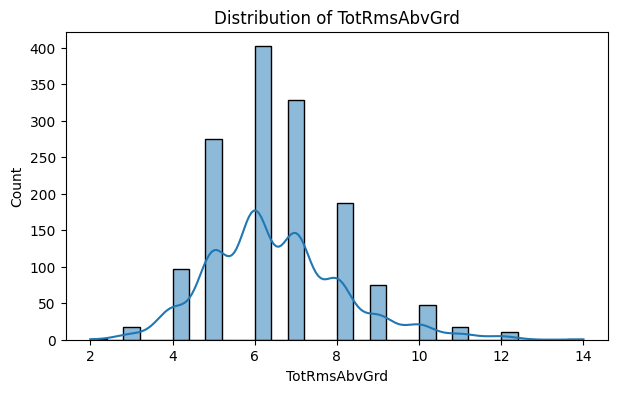

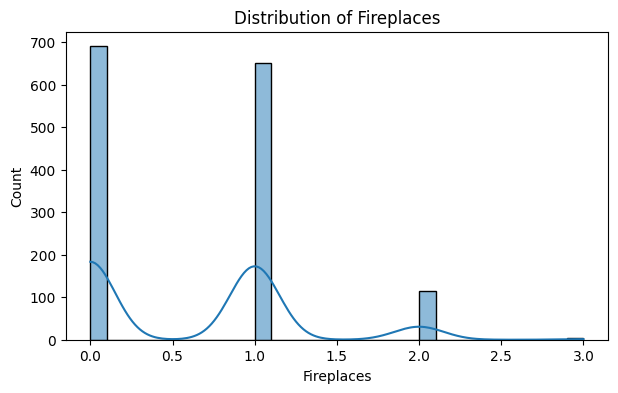

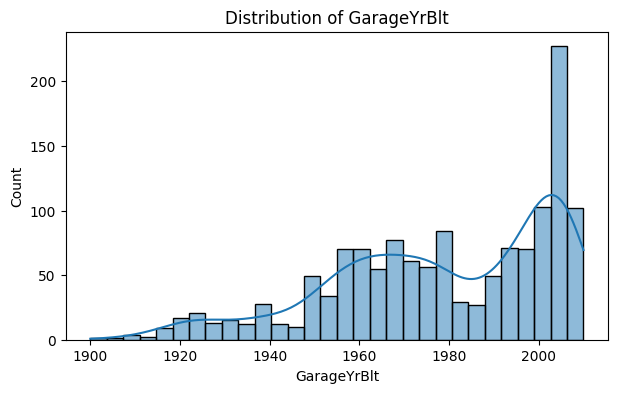

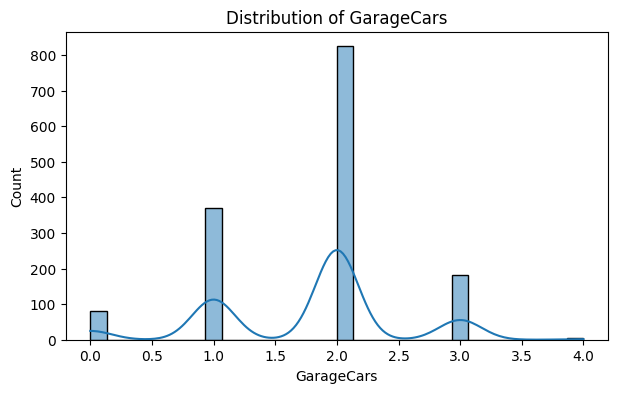

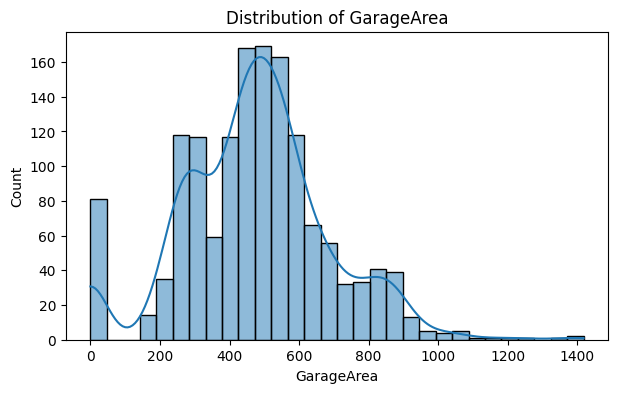

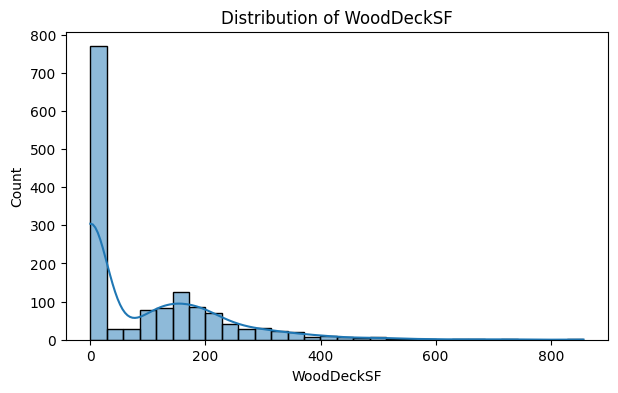

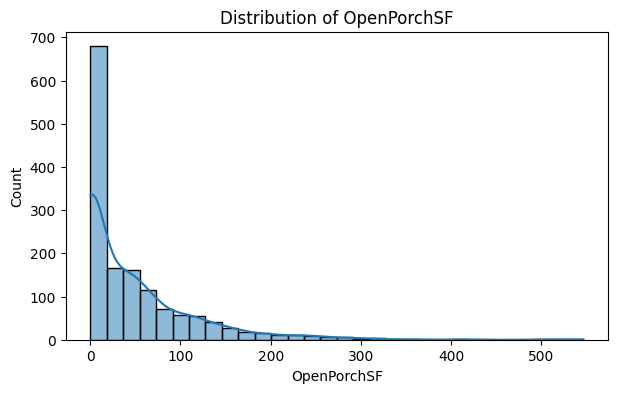

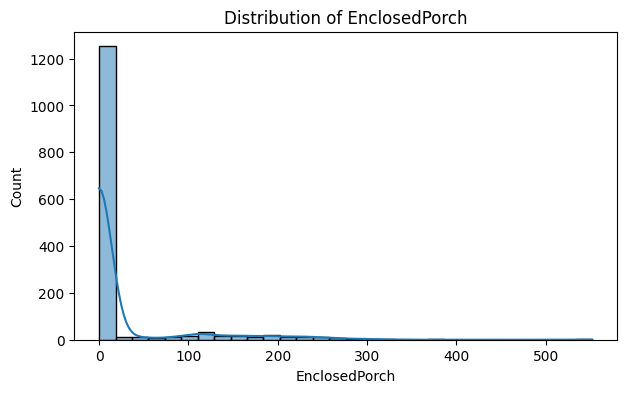

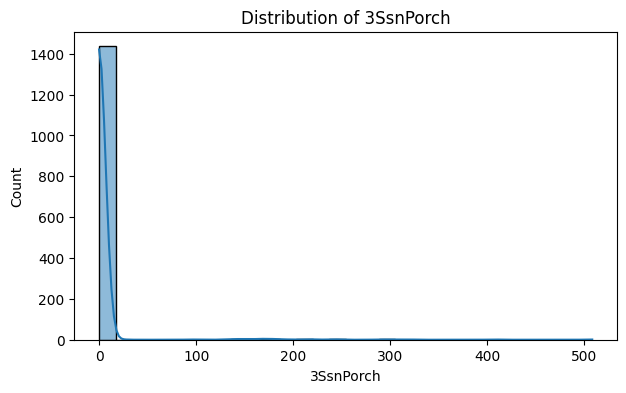

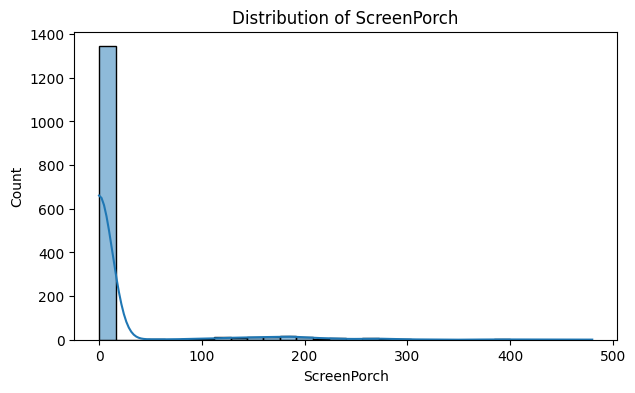

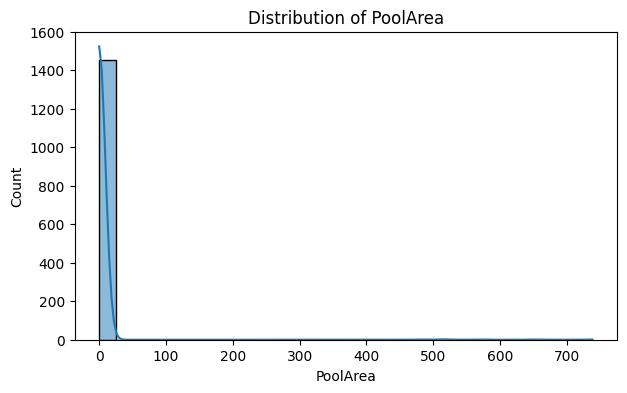

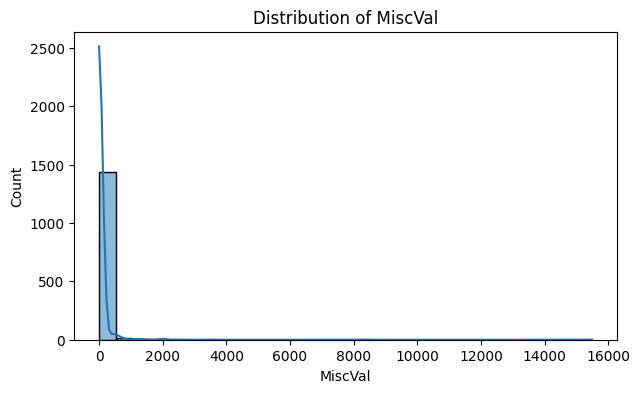

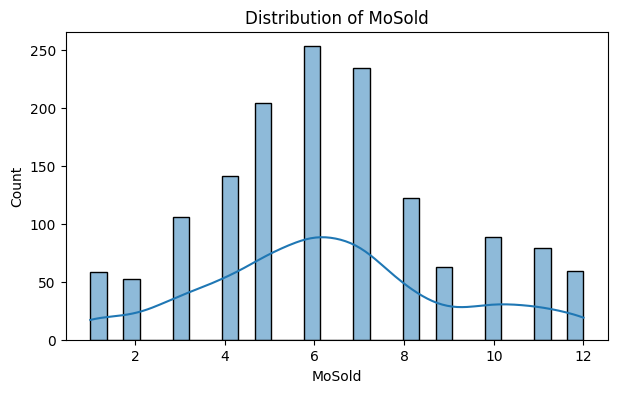

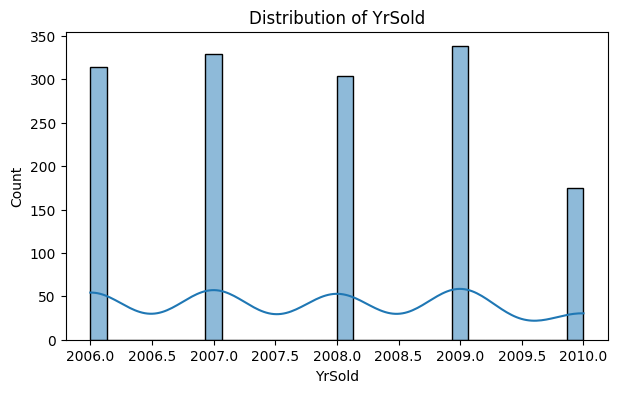

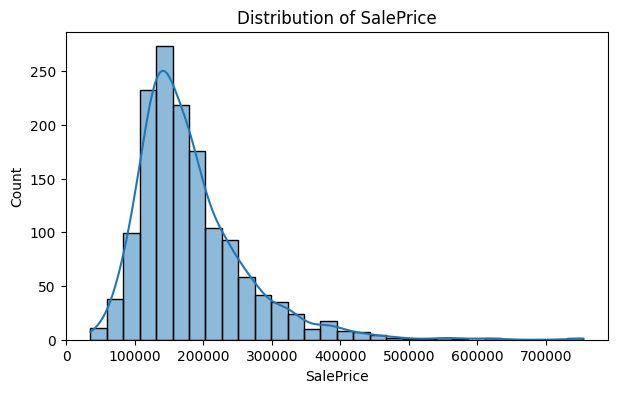

In [13]:


for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()


In [15]:
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[
      (df[col] < lower) |
      (df[col] > upper)
  ]


  print("Number of Outliers:", len(outliers))

Number of Outliers: 0
Number of Outliers: 103
Number of Outliers: 88
Number of Outliers: 69
Number of Outliers: 2
Number of Outliers: 125
Number of Outliers: 7
Number of Outliers: 0
Number of Outliers: 96
Number of Outliers: 7
Number of Outliers: 167
Number of Outliers: 29
Number of Outliers: 61
Number of Outliers: 20
Number of Outliers: 2
Number of Outliers: 26
Number of Outliers: 31
Number of Outliers: 1
Number of Outliers: 82
Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 35
Number of Outliers: 68
Number of Outliers: 30
Number of Outliers: 5
Number of Outliers: 0
Number of Outliers: 5
Number of Outliers: 21
Number of Outliers: 32
Number of Outliers: 77
Number of Outliers: 208
Number of Outliers: 24
Number of Outliers: 116
Number of Outliers: 7
Number of Outliers: 52
Number of Outliers: 0
Number of Outliers: 0
Number of Outliers: 61


In [17]:
for col in df.select_dtypes(include='object').columns:
  df[col].fillna(df[col].mode()[0], inplace=True)
for col in df.select_dtypes(include=['int64', 'float64']).columns:
  df[col].fillna(df[col].mean(), inplace=True)


/tmp/ipykernel_654/4190746911.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)
/tmp/ipykernel_654/4190746911.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

In [18]:
df.isnull().sum().sum()

np.int64(0)

In [19]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,730.5,Reg,Lvl,AllPub,...,0,730.5,730.5,730.5,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,730.5,Reg,Lvl,AllPub,...,0,730.5,730.5,730.5,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,730.5,IR1,Lvl,AllPub,...,0,730.5,730.5,730.5,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,730.5,IR1,Lvl,AllPub,...,0,730.5,730.5,730.5,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,730.5,IR1,Lvl,AllPub,...,0,730.5,730.5,730.5,0,12,2008,WD,Normal,250000


In [20]:
x=df.drop('SalePrice',axis=1)
y=df['SalePrice']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [22]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cat = x_train.select_dtypes(include='object')
for col in cat:
    combined_series = pd.concat([x_train[col], x_test[col]]).astype(str)
    le.fit(combined_series)
    x_train[col] = le.transform(x_train[col].astype(str))
    x_test[col] = le.transform(x_test[col].astype(str))



In [23]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
for i in x_train.select_dtypes(include='number'):
    x_train[[i]] = scalar.fit_transform(x_train[[i]])
    x_test[[i]] = scalar.transform(x_test[[i]])

In [24]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 48.9 MB/s  0:00:02


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [26]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [27]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

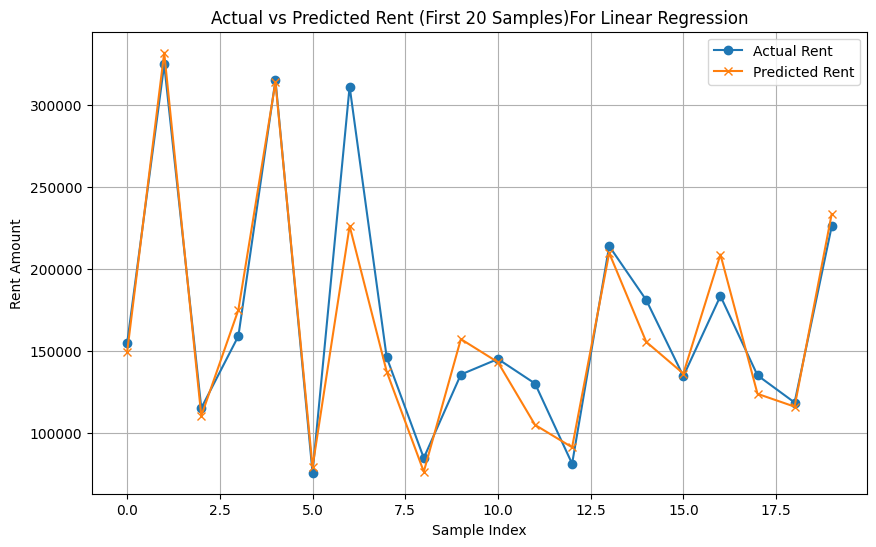

  7%|▋         | 1/15 [00:00<00:08,  1.75it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.459e+09, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(


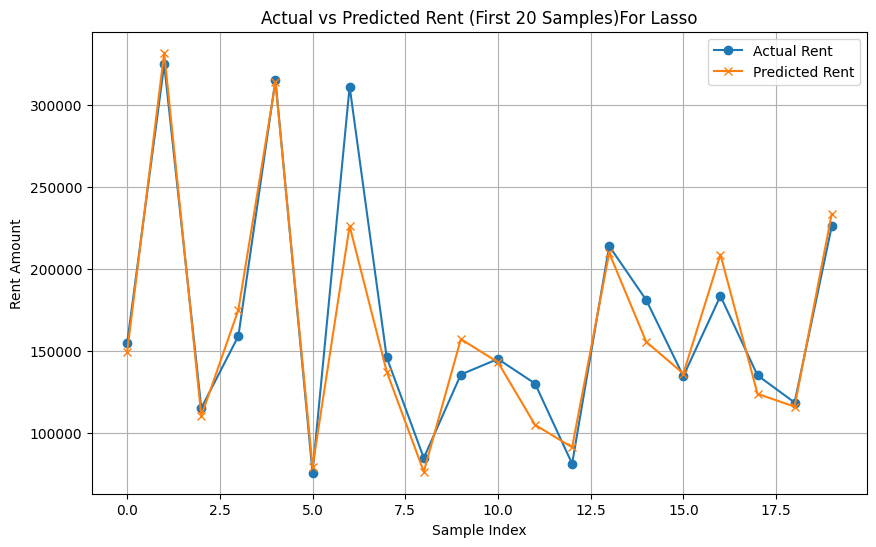

 13%|█▎        | 2/15 [00:01<00:06,  1.88it/s]

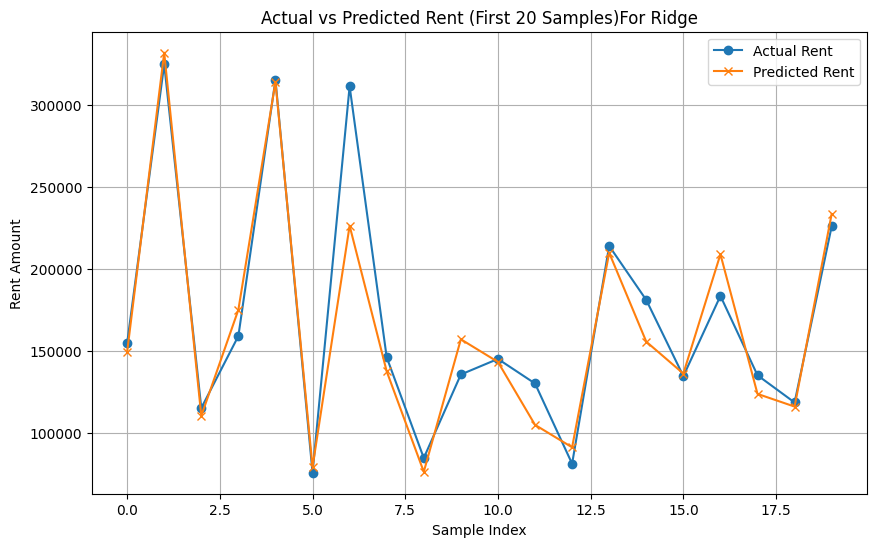

 20%|██        | 3/15 [00:01<00:05,  2.19it/s]

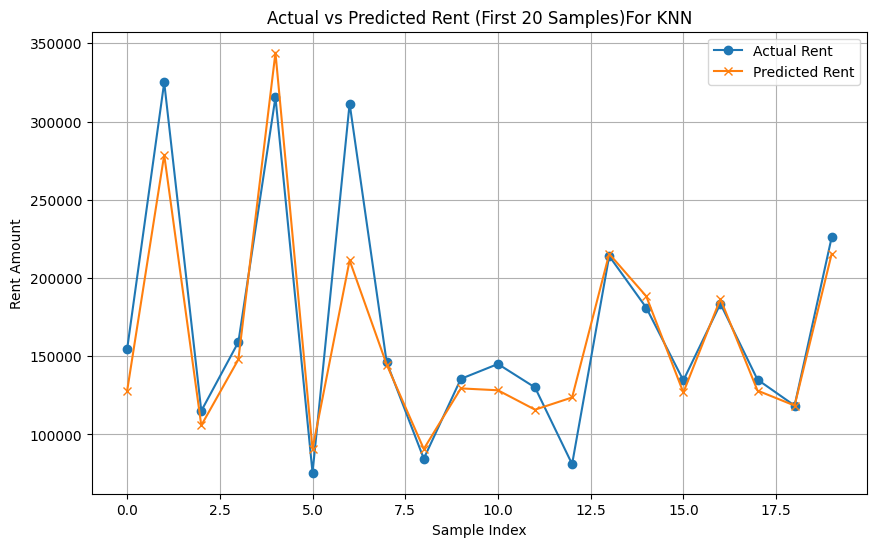

 27%|██▋       | 4/15 [00:02<00:06,  1.81it/s]

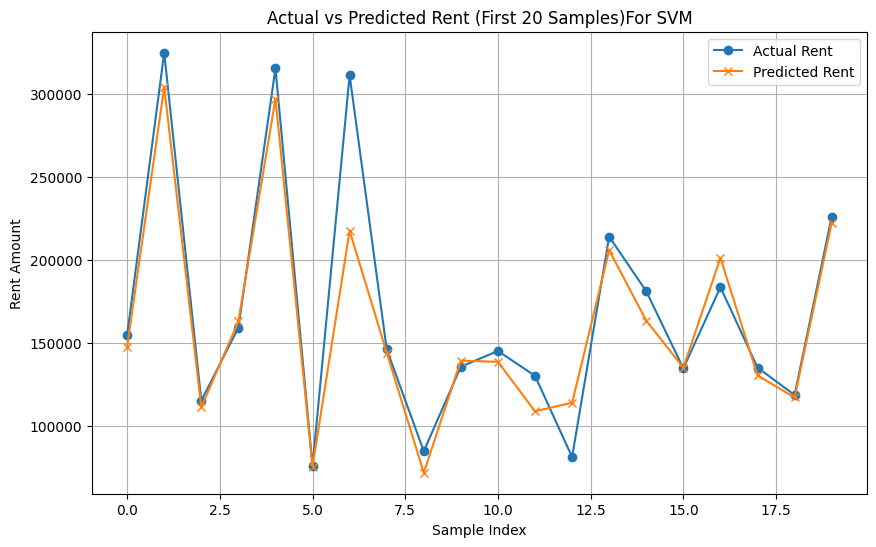

 33%|███▎      | 5/15 [00:02<00:05,  1.75it/s]

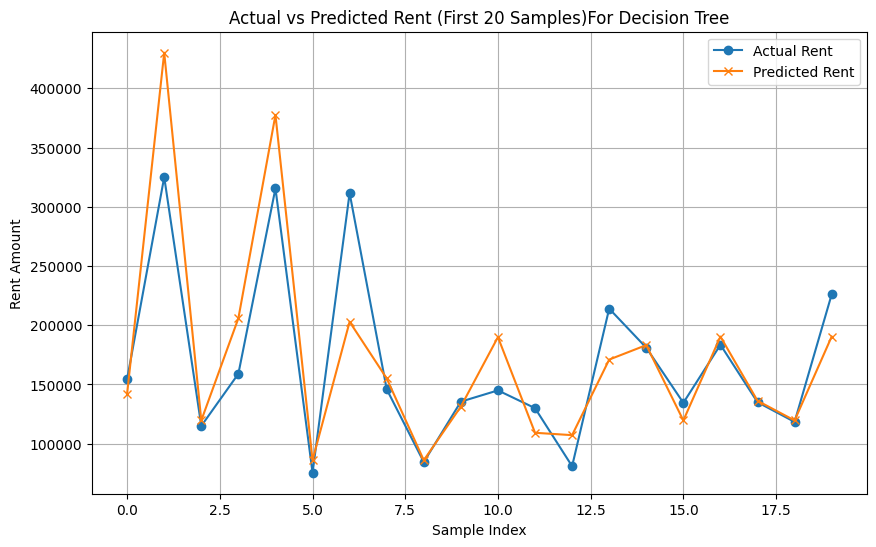

 40%|████      | 6/15 [00:03<00:04,  1.80it/s]

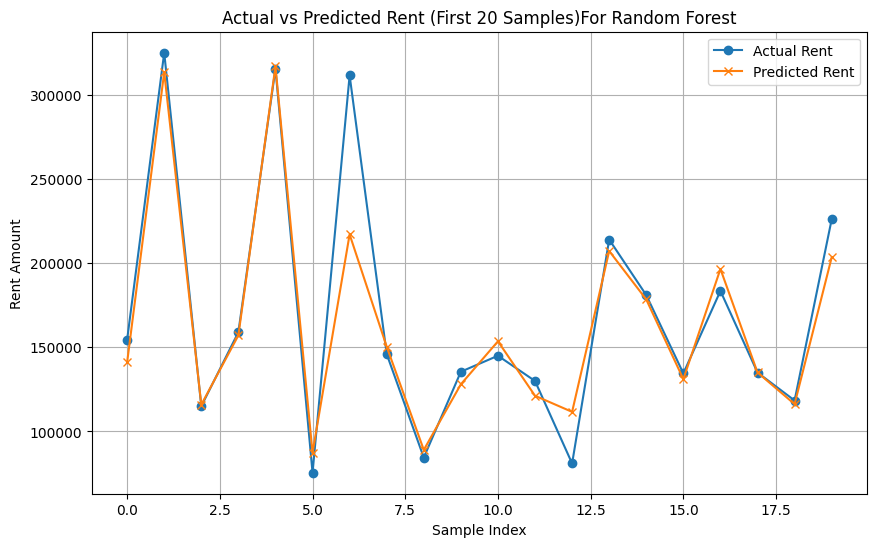

 47%|████▋     | 7/15 [00:04<00:06,  1.15it/s]

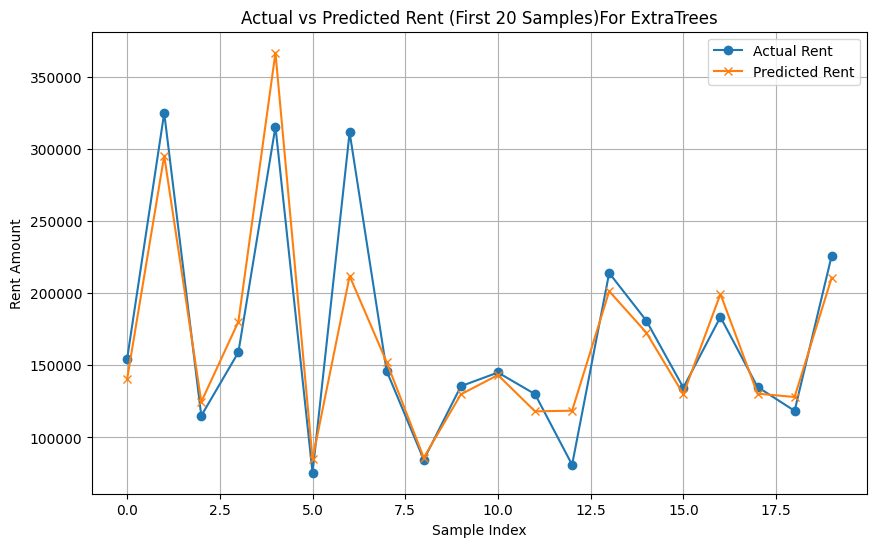

 53%|█████▎    | 8/15 [00:08<00:11,  1.65s/it]

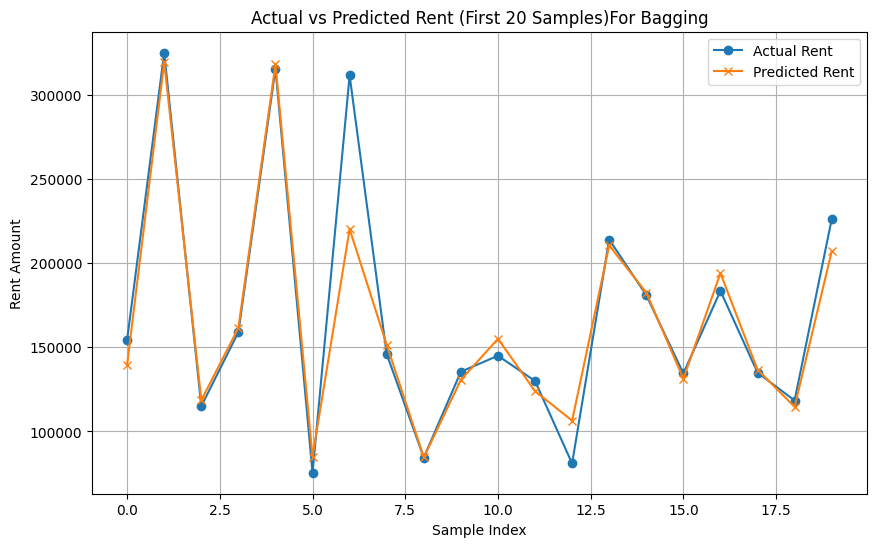

 60%|██████    | 9/15 [00:09<00:09,  1.63s/it]

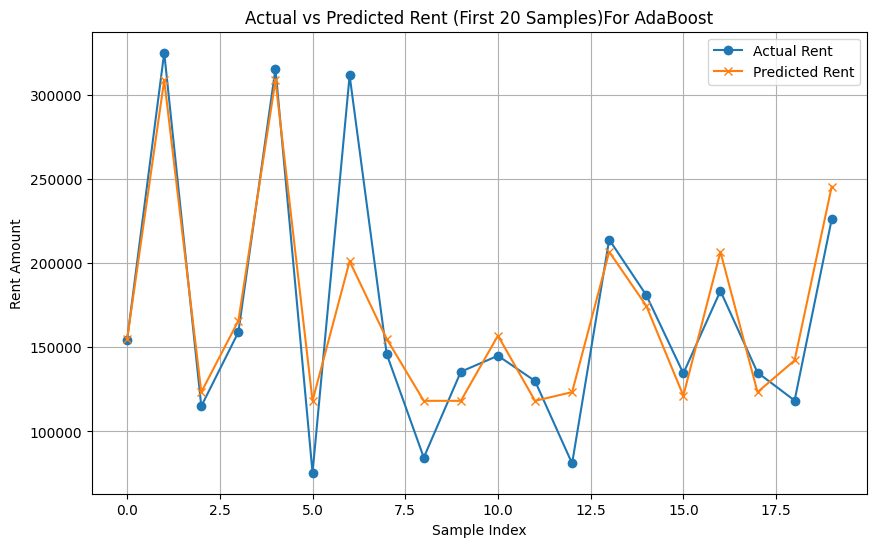

 67%|██████▋   | 10/15 [00:10<00:06,  1.24s/it]

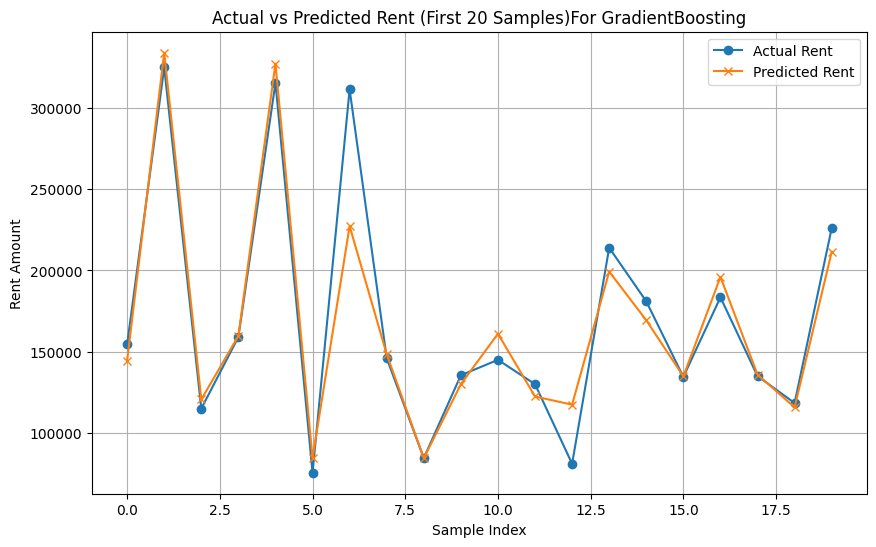

 73%|███████▎  | 11/15 [00:11<00:04,  1.23s/it]

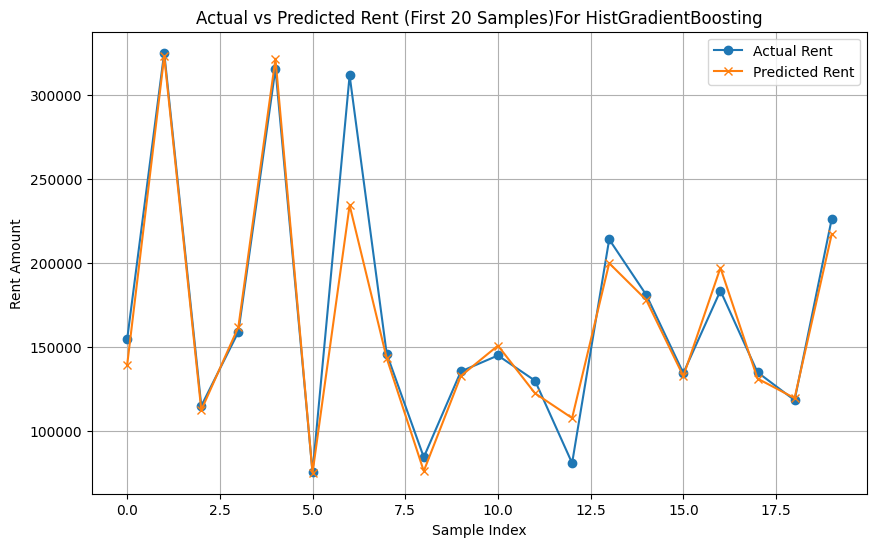

 80%|████████  | 12/15 [00:12<00:03,  1.13s/it]

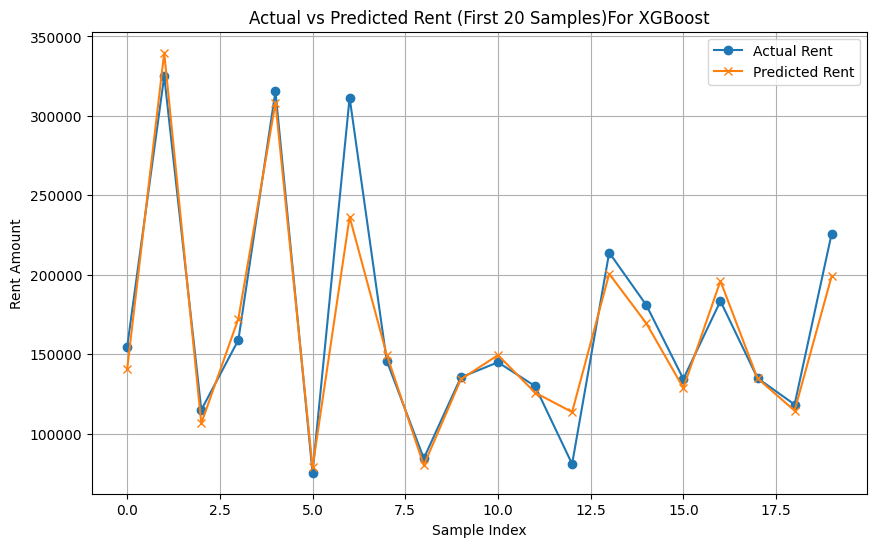

 87%|████████▋ | 13/15 [00:13<00:02,  1.05s/it]

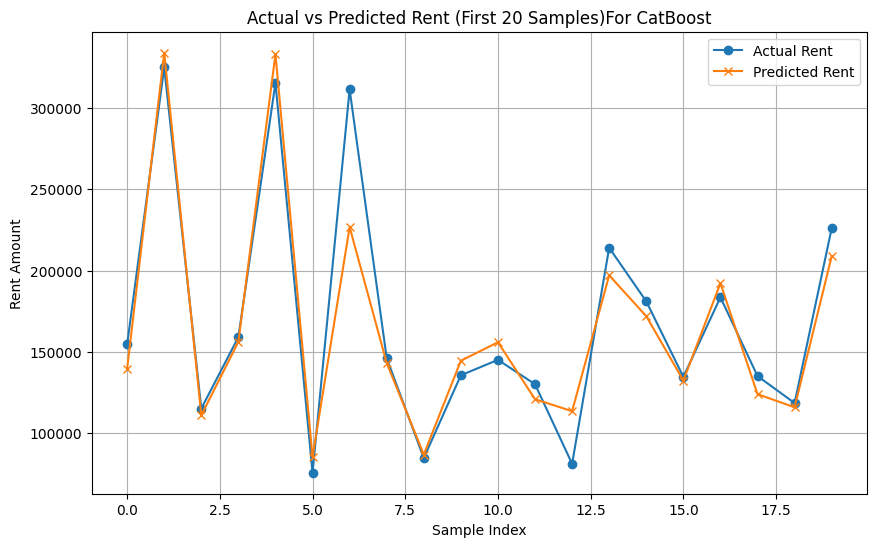

 93%|█████████▎| 14/15 [00:14<00:01,  1.07s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005811 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3440
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 74
[LightGBM] [Info] Start training from score 181441.541952


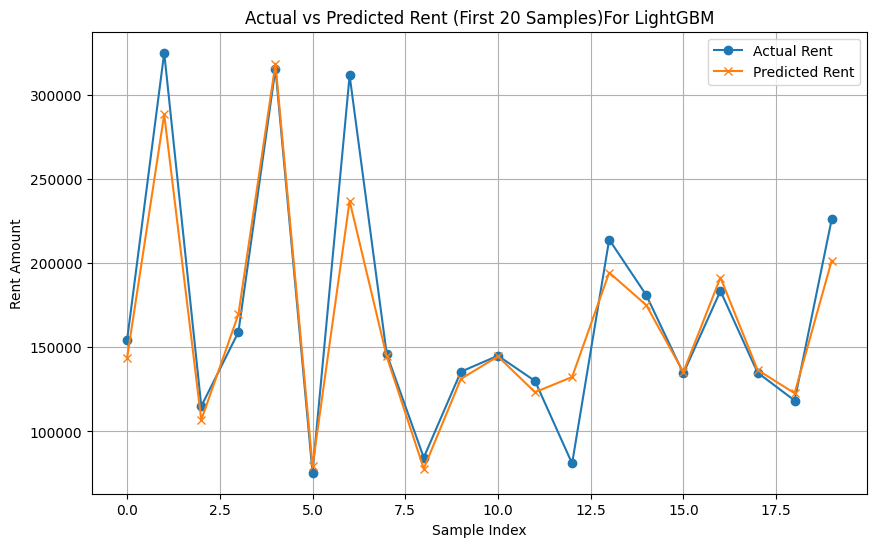

100%|██████████| 15/15 [00:15<00:00,  1.00s/it]


In [28]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(x_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, x_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, x_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(x_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [29]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(x_train, y_train)
model2.fit(x_train, y_train)
model3.fit(x_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, x_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, x_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, x_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [30]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(x_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, x_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [31]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,3597.810303,16434.695312,2.448476e+07,6.794070e+08,4948.207554,26065.436425,0.995895,0.911424
CatBoost,11450.111084,16974.730640,2.433565e+08,7.523169e+08,15599.887912,27428.395707,0.959200,0.901919
GradientBoosting,9999.278983,17014.562822,1.859087e+08,7.591912e+08,13634.834550,27553.424682,0.968831,0.901022
HistGradientBoosting,5073.566854,16548.978495,1.167845e+08,8.198976e+08,10806.689710,28633.854743,0.980420,0.893108
Bagging,8242.649058,18043.889055,1.619451e+08,8.458156e+08,12725.766703,29082.908473,0.972849,0.889729
ExtraTrees,0.000000,17823.271336,0.000000e+00,8.789887e+08,0.000000,29647.743443,1.000000,0.885404
LightGBM,5138.210715,16964.702340,1.209517e+08,8.796890e+08,10997.806042,29659.552170,0.979722,0.885313
Random Forest,8023.492421,18065.717317,1.475874e+08,8.977554e+08,12148.555979,29962.566086,0.975256,0.882957
Stacking,5939.624512,16964.702340,1.108544e+08,8.796890e+08,10528.743895,29659.552170,0.981414,0.879253
Simple Voting,7376.962764,16964.702340,1.407693e+08,8.796890e+08,11864.622678,29659.552170,0.976399,0.874143


<Axes: >

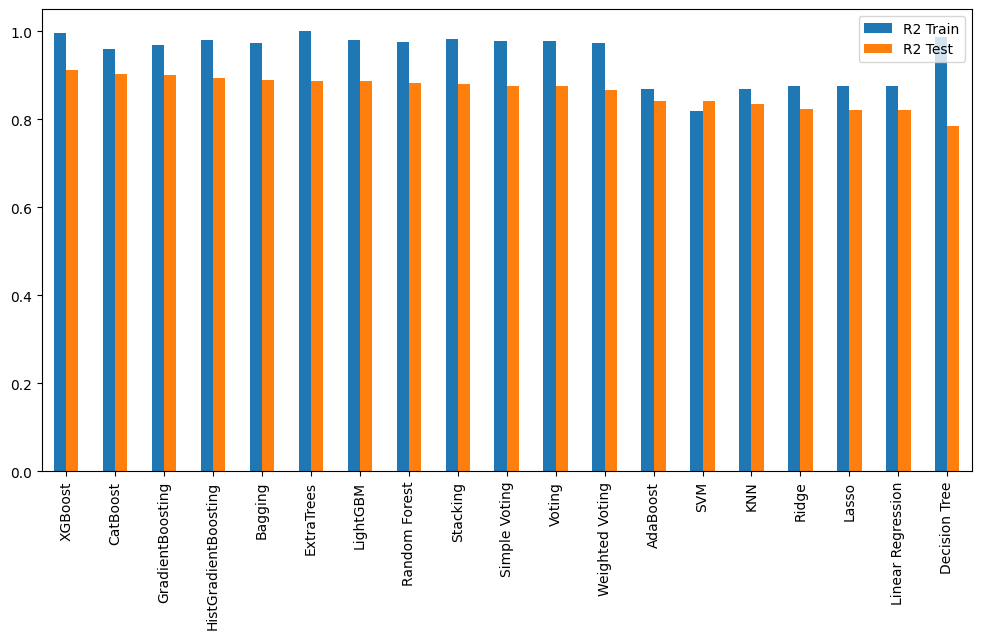

In [32]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

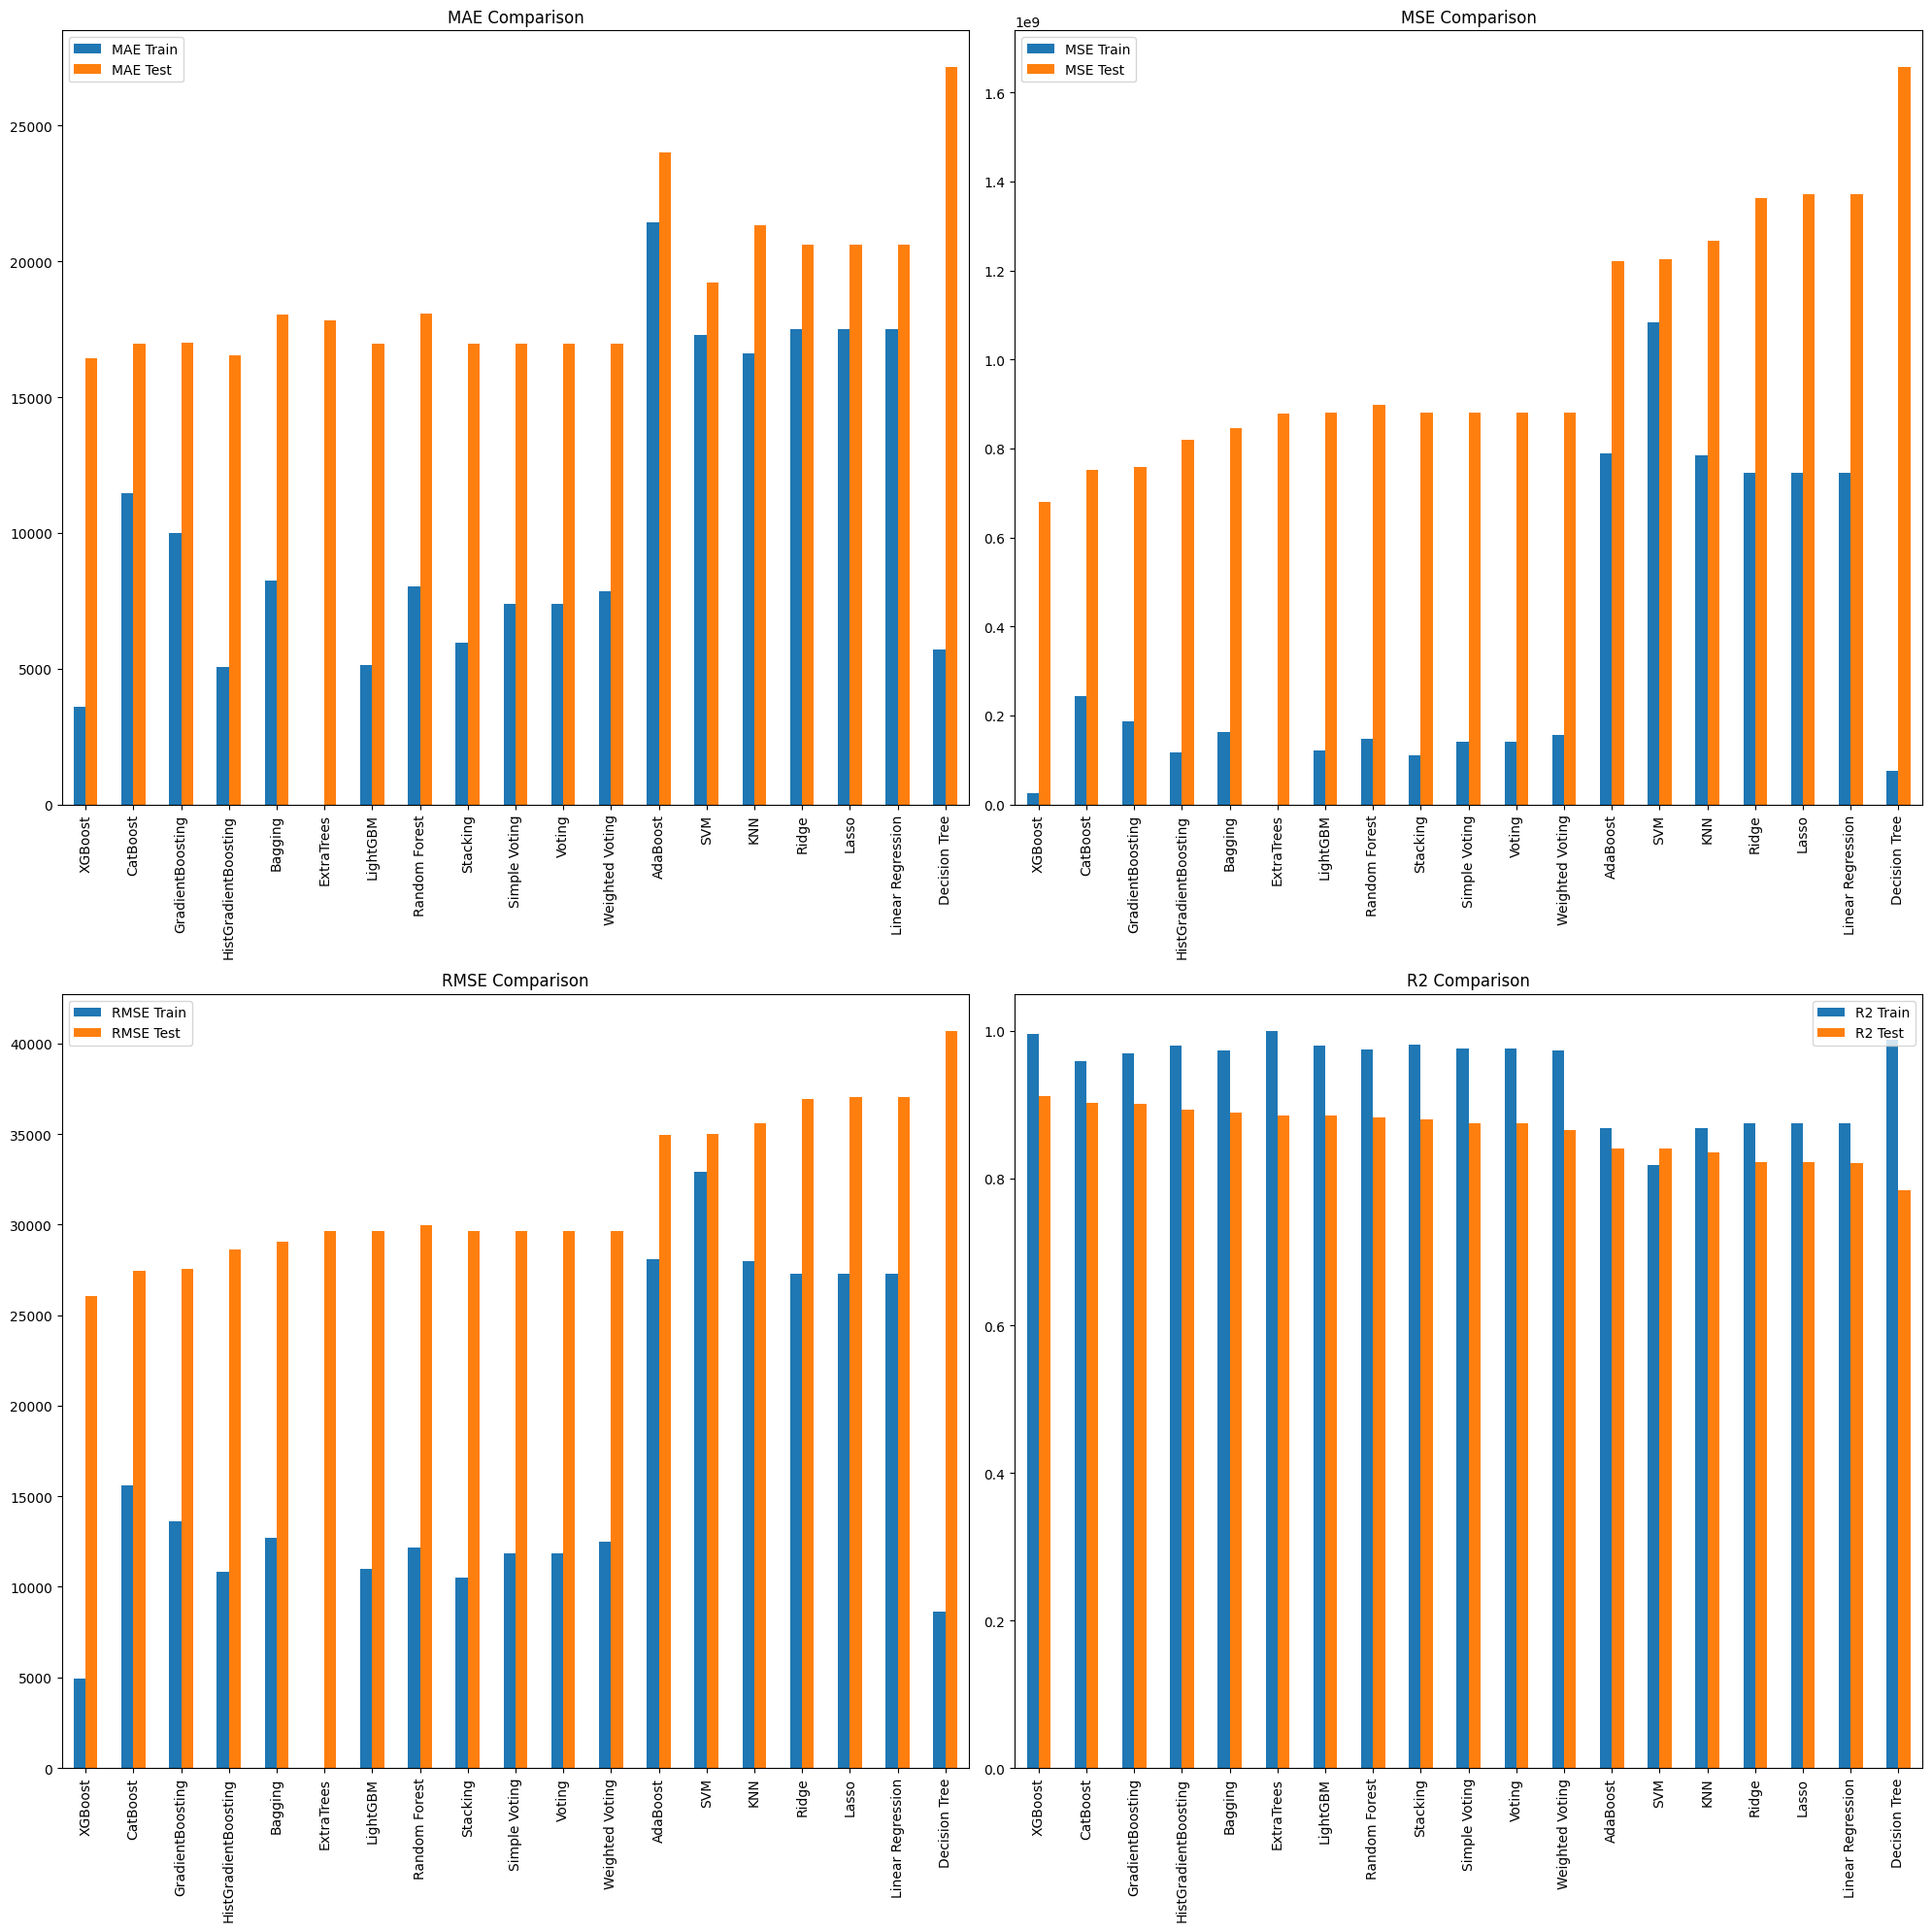

In [33]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [34]:
from sklearn.decomposition import PCA

print(x_train.shape)

pca = PCA(n_components=3,random_state=42)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)
print(x_test_pca.shape)

(1168, 80)
(292, 3)


<Figure size 1000x600 with 0 Axes>

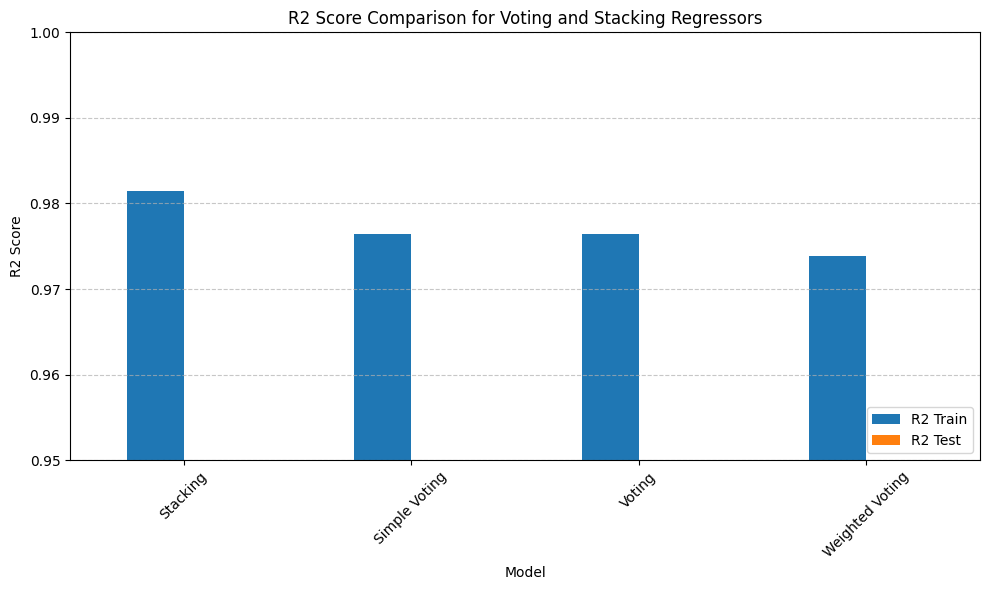

In [35]:

ensemble_models = ["Voting", "Simple Voting", "Weighted Voting", "Stacking"]
filtered_errors = errors_df.loc[errors_df.index.isin(ensemble_models)]

plt.figure(figsize=(10, 6))
filtered_errors[["R2 Train", "R2 Test"]].plot.bar(figsize=(10, 6))
plt.title("R2 Score Comparison for Voting and Stacking Regressors")
plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.ylim(0.95, 1.0)
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()